# Day 7 · Exploratory Data Analysis of the Simulated Supply-Chain Streams

**Phase 2 · Machine-learning model development** — this notebook is the evidence base for every modelling decision on Days 8–14 (statistical baselines, Isolation Forest, LSTM autoencoder, LSTM classifier, ensemble).

It answers six questions, one section each:

| § | Question | Feeds into |
|---|----------|-----------|
| 1 | How big is the data, how imbalanced are the classes, how dense is the stream over the day? | metrics, loss weighting, split strategy |
| 2 | What do warehouse anomalies (point / contextual / collective) look like, and how long does the signal "remember"? | statistical baselines, **LSTM lookback** |
| 3 | What do GPS anomalies look like in space, speed and route adherence? | feature priorities, rule baselines |
| 4 | What do inventory anomalies look like, and where does a pure magnitude rule break? | context features, classifier design |
| 5 | Which engineered features carry signal, which are redundant, and are the classes separable? | **feature list**, **Isolation-Forest contamination** |
| 6 | What do we decide? | Day 8–14 configuration |

**How the data is produced.** `SimulationOrchestrator.run_batch` generates 24 simulated hours (2026-11-20 00:00 UTC, seed 42, order stream off). Every event is pushed through the *production* `WindowedAggregator` (1 / 5 / 15-minute windows) and the Day 6 `FeatureEngineer`, so the feature matrices analysed in §5 are exactly what the online path will compute.

**Conventions.** Ground-truth labels (`is_anomaly`, `anomaly_type`, episode metadata) are used for *analysis only* and never as model inputs. Colour is consistent throughout: <span style="color:#9a9994">■ normal</span> · <span style="color:#e34948">■ point</span> · <span style="color:#6250d6">■ contextual</span> · <span style="color:#1baf7a">■ collective</span>; marker shapes repeat the type encoding so nothing relies on colour alone.

> **Extra dependencies** (not yet in `requirements.txt`): `seaborn`, `statsmodels`, `jupyter` / `ipykernel`, `nbformat` (and `nbconvert` to export HTML).

## 0 · Setup

In [1]:
from __future__ import annotations

import json
import math
import os
import sys
import time
import warnings
from collections import Counter
from datetime import UTC, datetime
from pathlib import Path

# Keep structlog quiet (the simulator logs one JSON line per stream); must precede project imports.
os.environ.setdefault("LOG_LEVEL", "WARNING")
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from plotly.subplots import make_subplots

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*is_sparse.*")
pd.set_option("display.max_columns", 60, "display.width", 160, "display.float_format", "{:,.4f}".format)

SEED = 42
rng = np.random.default_rng(SEED)

# ---- Palette (validated: point / contextual / collective pass the normal-vision floor;
# ---- colour-blind separation is backed up by marker symbols and direct labels) -----------
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
COL = {"normal": "#9a9994", "point": "#e34948", "contextual": "#6250d6", "collective": "#1baf7a"}
SYM = {"normal": "circle", "point": "x", "contextual": "diamond", "collective": "triangle-up"}
BLUE, ORANGE = "#2a78d6", "#eb6834"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]  # one-hue sequential
DIV_CMAP = LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f2ef", BLUE])
TYPES = ["normal", "point", "contextual", "collective"]

pio.templates["scad"] = go.layout.Template(
    layout=go.Layout(
        font=dict(family="Inter, Helvetica Neue, Arial, sans-serif", size=13, color=INK),
        paper_bgcolor=SURFACE, plot_bgcolor=SURFACE,
        colorway=[BLUE, ORANGE, "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"],
        xaxis=dict(gridcolor=GRID, linecolor=GRID, zeroline=False, ticks="outside", tickcolor=GRID, automargin=True),
        yaxis=dict(gridcolor=GRID, linecolor=GRID, zeroline=False, ticks="outside", tickcolor=GRID, automargin=True),
        # title and legend are positioned against the whole figure so they never collide with subplot titles
        legend=dict(orientation="h", yref="container", y=0.915, yanchor="top", xanchor="left", x=0),
        margin=dict(l=64, r=24, t=124, b=52),
        title=dict(x=0.0, xanchor="left", yref="container", y=0.985, yanchor="top", font=dict(size=17)),
        hoverlabel=dict(font_size=12),
    )
)
pio.templates.default = "scad"
pio.renderers.default = "plotly_mimetype+notebook_connected"

sns.set_theme(context="notebook", style="whitegrid", font="DejaVu Sans", rc={
    "axes.edgecolor": GRID, "grid.color": GRID, "axes.facecolor": SURFACE, "figure.facecolor": SURFACE,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "figure.dpi": 110, "savefig.dpi": 110,
})


def show(fig: go.Figure, height: int = 460, **layout) -> None:
    """Render a plotly figure with a fixed height."""
    fig.update_layout(height=height, **layout)
    fig.show()


def hdr(text: str) -> None:
    display(Markdown(text))


print(f"project root : {ROOT}")
print(f"python       : {sys.version.split()[0]}   numpy {np.__version__}   pandas {pd.__version__}")

project root : /home/claude/buildbyarindam/supply_chain_anomaly_detection_system
python       : 3.13.18   numpy 2.5.3   pandas 3.0.5


## 1 · Data loading & overview

### 1.1 Generate 24 simulated hours

`run_batch(3600)` is called 24 times — the orchestrator continues exactly where the previous call stopped, so this equals one `run_batch(86_400)` but keeps memory bounded (one simulated hour ≈ 54 000 events). Each hour is flattened into tabular rows, and the same events are fed to the production `WindowedAggregator`; the resulting 1/5/15-minute bundles are vectorised by `FeatureEngineer`.

*Mapping note.* The event→(signals, context) mapping below mirrors `src.kafka.stream_processor.extract_signals` without building a pydantic `KafkaMessage` per event (1.3 M of them would dominate the run time). Window, watermark and feature code are the real implementations.

In [2]:
from src.data_simulation.orchestrator import SimulationOrchestrator
from src.kafka.stream_processor import WindowedAggregator, parse_event_time
from src.models.feature_engineering import FeatureEngineer, bundles_from_features
from src.utils.config import get_config

cfg = get_config()
START = datetime(2026, 11, 20, 0, 0, 0, tzinfo=UTC)
HOURS = 24
SOURCES = ["warehouse", "vehicle", "inventory"]
WINDOWS = tuple(cfg.features.window_seconds)

orc = SimulationOrchestrator.from_config(cfg.simulation, start_time=START, include_orders=False)
agg = WindowedAggregator(WINDOWS, cfg.features.watermark_tolerance_s)
engineer = FeatureEngineer(zones=cfg.simulation.warehouse.zones)  # no EntityHistory feedback offline
FNAMES = {s: engineer.names(s) for s in SOURCES}

wh_rows, gps_rows, inv_rows = [], [], []
feat_X = {s: [] for s in SOURCES}
feat_meta = {s: [] for s in SOURCES}
status = Counter()
t0 = time.time()

for hour in range(HOURS):
    emitted = []
    for ev in orc.run_batch(3600):
        p, st, md = ev["payload"], ev["source_type"], ev["payload"]["metadata"]
        if st == "warehouse":
            lo, hi = md["acceptable_range"]
            wh_rows.append((p["sensor_id"], p["warehouse_id"], p["timestamp"], p["reading_type"], p["value"],
                            p["is_anomaly"], p["anomaly_type"], md["zone"], md["storage_type"], lo, hi,
                            md.get("episode_id"), md.get("episode_step")))
            sig = {"value": p["value"]}
            ctx = {**md, "warehouse_id": p["warehouse_id"], "reading_type": p["reading_type"], "unit": p["unit"]}
        elif st == "vehicle":
            gps_rows.append((p["vehicle_id"], p["timestamp"], p["latitude"], p["longitude"], p["speed_kmh"],
                             p["heading"], p["route_adherence_score"], p["is_anomaly"], p["anomaly_type"],
                             md["route_id"], md["trip"], md["progress_m"], md["distance_from_route_m"],
                             md["cruise_speed_kmh"], md.get("anomaly_subtype"), md.get("episode_id"),
                             md.get("episode_step")))
            sig = {"speed_kmh": p["speed_kmh"], "route_adherence_score": p["route_adherence_score"]}
            ctx = {**md, "latitude": p["latitude"], "longitude": p["longitude"], "heading": p["heading"]}
        else:
            inv_rows.append((p["sku_id"], p["warehouse_id"], p["timestamp"], p["previous_level"], p["new_level"],
                             p["change_amount"], p["transaction_type"], p["is_anomaly"], p["anomaly_type"],
                             md["zone"], md["min_stock"], md["max_stock"], md["reorder_point"],
                             md.get("anomaly_subtype"), md.get("episode_id"), md.get("episode_step")))
            sig = {"new_level": float(p["new_level"]), "change_amount": float(p["change_amount"])}
            ctx = {**md, "warehouse_id": p["warehouse_id"], "transaction_type": p["transaction_type"]}
        out = agg.update(ev["entity_id"], st, parse_event_time(ev["timestamp"]), sig, context=ctx,
                         is_anomaly=p["is_anomaly"], anomaly_type=p["anomaly_type"])
        status[out.status] += 1
        if out.status == "emitted":
            emitted.extend(out.features)
    for b in bundles_from_features(emitted, WINDOWS):
        feat_X[b.source_type].append(engineer.vectorize(b))
        s = b.short
        feat_meta[b.source_type].append((b.entity_id, b.window_end, s.label_is_anomaly, s.label_anomaly_type))
    del emitted

print(f"simulated {HOURS} h in {time.time() - t0:,.0f} s   aggregator outcomes: {dict(status)}")
print("orchestrator ground-truth counters:", {k: v for k, v in orc.stats.items()})

simulated 24 h in 111 s   aggregator outcomes: {'emitted': 1296098}
orchestrator ground-truth counters: {'warehouse': {'events': 1036800, 'anomalies': 34984}, 'vehicle': {'events': 43200, 'anomalies': 944}, 'inventory': {'events': 216098, 'anomalies': 1890}}


In [3]:
def _ts(s: pd.Series) -> pd.Series:
    return pd.to_datetime(s, utc=True, format="ISO8601")


wh = pd.DataFrame(wh_rows, columns=["sensor_id", "warehouse_id", "ts", "reading_type", "value", "is_anomaly",
                                    "anomaly_type", "zone", "storage_type", "acc_lo", "acc_hi", "episode_id",
                                    "episode_step"])
gps = pd.DataFrame(gps_rows, columns=["vehicle_id", "ts", "lat", "lon", "speed", "heading", "adherence",
                                      "is_anomaly", "anomaly_type", "route_id", "trip", "progress_m", "dist_m",
                                      "cruise", "subtype", "episode_id", "episode_step"])
inv = pd.DataFrame(inv_rows, columns=["sku_id", "warehouse_id", "ts", "prev", "new", "chg", "ttype", "is_anomaly",
                                      "anomaly_type", "zone", "min_stock", "max_stock", "reorder_point", "subtype",
                                      "episode_id", "episode_step"])
del wh_rows, gps_rows, inv_rows

for df in (wh, gps, inv):
    df["ts"] = _ts(df["ts"])
    df["label"] = df["anomaly_type"].fillna("normal")
    df["hour"] = df["ts"].dt.hour
gps["subtype"] = gps["subtype"].fillna("normal")
inv["subtype"] = inv["subtype"].fillna("normal")
gps["speed_ratio"] = gps["speed"] / gps["cruise"]

# Feature matrices (one row per event, 3 windows each) with their ground-truth labels
F = {}
for s in SOURCES:
    m = pd.DataFrame(feat_meta[s], columns=["entity_id", "ts", "is_anomaly", "anomaly_type"])
    m["ts"] = pd.to_datetime(m["ts"], utc=True)
    m["label"] = m["anomaly_type"].fillna("normal")
    F[s] = pd.concat([m, pd.DataFrame(np.vstack(feat_X[s]).astype(np.float32), columns=FNAMES[s])], axis=1)
del feat_X, feat_meta

# Static lookups from the simulators
ITEMS = {i.sku_id: i for i in orc.inventory.items}
inv["max_ship"] = inv["sku_id"].map(lambda k: ITEMS[k].max_shipment)
VEHICLES = {v.vehicle_id: v for v in orc.vehicles.vehicles}

print(f"warehouse {wh.shape}   vehicle {gps.shape}   inventory {inv.shape}")
print({s: F[s].shape for s in SOURCES}, "<- feature frames (meta + features)")
print("feature counts:", {s: len(FNAMES[s]) for s in SOURCES})

warehouse (1036800, 15)   vehicle (43200, 20)   inventory (216098, 19)
{'warehouse': (1036800, 35), 'vehicle': (43200, 46), 'inventory': (216098, 47)} <- feature frames (meta + features)
feature counts: {'warehouse': 30, 'vehicle': 41, 'inventory': 42}


### 1.2 Overview and summary statistics

In [4]:
overview = pd.DataFrame({
    "events": {"warehouse": len(wh), "vehicle": len(gps), "inventory": len(inv)},
    "entities": {"warehouse": wh.sensor_id.nunique(), "vehicle": gps.vehicle_id.nunique(), "inventory": inv.sku_id.nunique()},
    "event interval": {"warehouse": "1 s / sensor", "vehicle": "10 s / vehicle",
                       "inventory": f"irregular (~{86400 / (len(inv) / inv.sku_id.nunique()):.0f} s / SKU)"},
    "anomalous events": {"warehouse": int(wh.is_anomaly.sum()), "vehicle": int(gps.is_anomaly.sum()), "inventory": int(inv.is_anomaly.sum())},
})
overview["anomaly rate"] = overview["anomalous events"] / overview["events"]
overview["span"] = f"{wh.ts.min():%Y-%m-%d %H:%M} → {wh.ts.max():%H:%M} UTC"
display(overview)

hdr("**Warehouse sensors — normal readings only, by sensor type and zone** (zone A = cold storage, B = dry goods, C = ambient)")
display(wh[~wh.is_anomaly].groupby(["reading_type", "zone"]).value.describe(percentiles=[.01, .5, .99]).round(3))
hdr("**GPS vehicles — normal readings only**")
display(gps[~gps.is_anomaly][["speed", "speed_ratio", "adherence", "dist_m", "cruise"]].describe(percentiles=[.01, .5, .99]).T.round(3))
hdr("**Inventory — normal events only**")
display(inv[~inv.is_anomaly][["new", "chg", "max_ship"]].describe(percentiles=[.01, .5, .99]).T.round(3))
display(inv[~inv.is_anomaly].groupby("ttype").chg.agg(["count", "mean", "min", "max"]).round(2))

,events,entities,event interval,anomalous events,anomaly rate,span
warehouse,1036800,12,1 s / sensor,34984,0.0337,2026-11-20 00:00 → 23:59 UTC
vehicle,43200,5,10 s / vehicle,944,0.0219,2026-11-20 00:00 → 23:59 UTC
inventory,216098,50,irregular (~20 s / SKU),1890,0.0087,2026-11-20 00:00 → 23:59 UTC


**Warehouse sensors — normal readings only, by sensor type and zone** (zone A = cold storage, B = dry goods, C = ambient)

count    mean    std     min      1%     50%     99%     max
reading_type zone                                                                    
humidity     A    167,171.0000 88.3040 1.8180 80.0200 84.0680 88.3040 92.5530 94.9950
             B    167,099.0000 45.4160 2.5360 35.0670 39.4960 45.4180 51.3010 54.9960
             C    166,673.0000 50.5220 3.0310 36.3310 43.4910 50.5280 57.5710 64.2940
temperature  A    167,164.0000  3.0420 0.2530  2.0030  2.4520  3.0430  3.6270  3.9880
             B    166,939.0000 20.0880 0.5040 18.1180 18.9130 20.0880 21.2640 21.9910
             C    166,770.0000 21.2070 1.2140 15.2790 18.3770 21.2100 24.0370 26.7650

**GPS vehicles — normal readings only**

,count,mean,std,min,1%,50%,99%,max
speed,"42,256.0000",64.5270,7.6890,42.2900,50.1460,63.6200,81.0600,88.0500
speed_ratio,"42,256.0000",1.0000,0.0600,0.7430,0.8610,1.0000,1.1380,1.2000
adherence,"42,256.0000",1.0000,0.0000,0.9960,0.9980,1.0000,1.0000,1.0000
dist_m,"42,256.0000",3.1900,2.4030,0.0000,0.1000,2.7000,10.3000,16.8000
cruise,"42,256.0000",64.5080,6.6600,55.6000,55.6000,61.9000,73.4000,73.4000


**Inventory — normal events only**

,count,mean,std,min,1%,50%,99%,max
new,"214,208.0000",280.3830,268.8800,10.0000,26.0000,183.0000,"1,163.0000","1,943.0000"
chg,"214,208.0000",0.1670,73.8210,-76.0000,-70.0000,-7.0000,350.0000,731.0000
max_ship,"214,208.0000",26.9030,22.7000,8.0000,8.0000,19.0000,76.0000,76.0000


,count,mean,min,max
ttype,,,,
adjustment,3963,-0.0300,-3,3
restock,12060,224.7700,59,731
return,6066,2.0300,1,3
shipment,192119,-13.9900,-76,-1


### 1.3 Class imbalance — normal vs each anomaly type

Two levels matter and they tell different stories: **rows** (what a per-event classifier sees) and **episodes** (how many independent anomalous incidents exist; the effective sample size for generalisation, and the unit that must never be split across train/test).

In [5]:
def imbalance_table(df: pd.DataFrame, source: str, entity: str, by: str = "label") -> pd.DataFrame:
    n = len(df)
    rows = []
    for cls, g in df.groupby(by):
        eps = g.dropna(subset=["episode_id"]).groupby([entity, "episode_id"]).ngroups if cls != "normal" else np.nan
        rows.append({"source": source, "class": cls, "rows": len(g), "% of rows": 100 * len(g) / n,
                     "normal : class": (df[by].eq("normal").sum() / len(g)) if cls != "normal" else 1.0,
                     "episodes": eps, "rows / episode": len(g) / eps if cls != "normal" and eps else np.nan})
    return pd.DataFrame(rows)

imb = pd.concat([
    imbalance_table(wh, "warehouse", "sensor_id"),
    imbalance_table(gps, "vehicle", "vehicle_id"),
    imbalance_table(gps[gps.is_anomaly], "vehicle (subtype)", "vehicle_id", by="subtype"),
    imbalance_table(inv, "inventory", "sku_id"),
    imbalance_table(inv[inv.is_anomaly], "inventory (subtype)", "sku_id", by="subtype"),
], ignore_index=True)
display(imb.style.format({"rows": "{:,.0f}", "% of rows": "{:.3f}", "normal : class": "{:,.0f}", "episodes": "{:,.0f}",
                          "rows / episode": "{:.1f}"}, na_rep="–").hide(axis="index"))

# Plot: rows per class per source (log scale — the imbalance IS the point)
plot_rows = imb[imb.source.isin(["warehouse", "vehicle", "inventory"])]
fig = go.Figure()
for cls in TYPES:
    d = plot_rows[plot_rows["class"] == cls]
    fig.add_bar(x=d.source, y=d.rows, name=cls, marker_color=COL[cls], marker_line=dict(color=SURFACE, width=2),
                text=[f"{v:,.0f}<br>({p:.2f}%)" for v, p in zip(d.rows, d["% of rows"])], textposition="outside",
                hovertemplate="%{x} · " + cls + "<br>%{y:,} rows<extra></extra>")
fig.update_layout(barmode="group", yaxis=dict(type="log", title="rows (log scale)", range=[2, 7]),
                  title="Class balance per source — rows per class (log y)")
show(fig, 470)

source,class,rows,% of rows,normal : class,episodes,rows / episode
warehouse,collective,"5,091",0.491,197,257,19.8
warehouse,contextual,"10,051",0.969,100,"1,555",6.5
warehouse,normal,"1,001,816",96.626,1,–,–
warehouse,point,"19,842",1.914,50,"6,696",3.0
vehicle,collective,344,0.796,123,17,20.2
vehicle,normal,"42,256",97.815,1,–,–
vehicle,point,600,1.389,70,110,5.5
vehicle (subtype),excessive_speed,102,10.805,0,27,3.8
vehicle (subtype),gradual_delay,344,36.441,0,17,20.2
vehicle (subtype),route_deviation,383,40.572,0,53,7.2


### 1.4 Event density and anomaly density over the day

In [6]:
dens = pd.concat([
    wh.groupby("hour").agg(events=("value", "size"), anomalies=("is_anomaly", "sum")).assign(source="warehouse"),
    gps.groupby("hour").agg(events=("speed", "size"), anomalies=("is_anomaly", "sum")).assign(source="vehicle"),
    inv.groupby("hour").agg(events=("new", "size"), anomalies=("is_anomaly", "sum")).assign(source="inventory"),
]).reset_index()
dens["anomaly rate %"] = 100 * dens.anomalies / dens.events

# warehouse episodes *starting* per hour and type (rows are autocorrelated; episodes are the incidents)
first = wh[wh.is_anomaly].sort_values("ts").groupby(["sensor_id", "episode_id"]).first().reset_index()
starts = first.groupby(["hour", "label"]).size().unstack(fill_value=0).reindex(range(24), fill_value=0)

fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.07, row_heights=[0.34, 0.33, 0.33],
                    subplot_titles=("Events per hour (log)", "Anomalous share of events per hour (%)",
                                    "Warehouse anomaly episodes started per hour, by type"))
line_col = {"warehouse": BLUE, "vehicle": ORANGE, "inventory": "#eda100"}
for src in SOURCES:
    d = dens[dens.source == src]
    fig.add_scatter(x=d.hour, y=d.events, name=src, mode="lines+markers", line=dict(color=line_col[src], width=2),
                    marker=dict(size=7, line=dict(color=SURFACE, width=1.5)), legendgroup=src, row=1, col=1)
    fig.add_scatter(x=d.hour, y=d["anomaly rate %"], name=src, mode="lines+markers", showlegend=False,
                    line=dict(color=line_col[src], width=2), marker=dict(size=7, line=dict(color=SURFACE, width=1.5)),
                    legendgroup=src, row=2, col=1)
for t in ["point", "contextual", "collective"]:
    fig.add_bar(x=starts.index, y=starts[t], name=f"{t} episodes", marker_color=COL[t],
                marker_line=dict(color=SURFACE, width=2), row=3, col=1)
fig.update_yaxes(type="log", tickvals=[1_000, 10_000, 100_000], ticktext=["1k", "10k", "100k"], range=[2.9, 5.0], row=1, col=1)
fig.update_layout(barmode="stack", title="Event & anomaly density over the simulated day")
fig.update_xaxes(title_text="hour of day (UTC)", dtick=2, row=3, col=1)
for r in (1, 2, 3):
    fig.add_vrect(x0=-0.5, x1=4.5, fillcolor=COL["contextual"], opacity=0.07, line_width=0, row=r, col=1)
fig.add_annotation(x=2, y=1.0, xref="x3", yref="y3 domain", text="off-hours 00–05", showarrow=False,
                   yanchor="bottom", font=dict(color=COL["contextual"], size=11))
show(fig, 780)
off = wh[wh.hour < 5]
print(f"Contextual warehouse rows inside off-hours (00-05): "
      f"{(wh[wh.label == 'contextual'].hour < 5).mean():.1%}   |   volume per hour is constant by construction "
      f"(1 s / 10 s ticks), so stream-rate alone carries no anomaly signal.")

Contextual warehouse rows inside off-hours (00-05): 100.0%   |   volume per hour is constant by construction (1 s / 10 s ticks), so stream-rate alone carries no anomaly signal.


---
## 2 · Warehouse sensor EDA

Three anomaly mechanisms are injected (see `warehouse_simulator.py`):

* **point** — a spike *outside* the acceptable range lasting 1–5 readings;
* **contextual** — readings *inside* the acceptable range but with a business-hours signature during off-hours (00:00–05:00);
* **collective** — a gradual drift over 10–30 readings; single readings look unremarkable, the *sequence* is the anomaly.

### 2.1 Reading distributions per zone (KDE), anomalies highlighted
Dashed lines mark the sensor's acceptable range. Each class is normalised separately (`common_norm=False`) so the rare classes are visible; the normal class is a 60 k sample of the zone's readings.

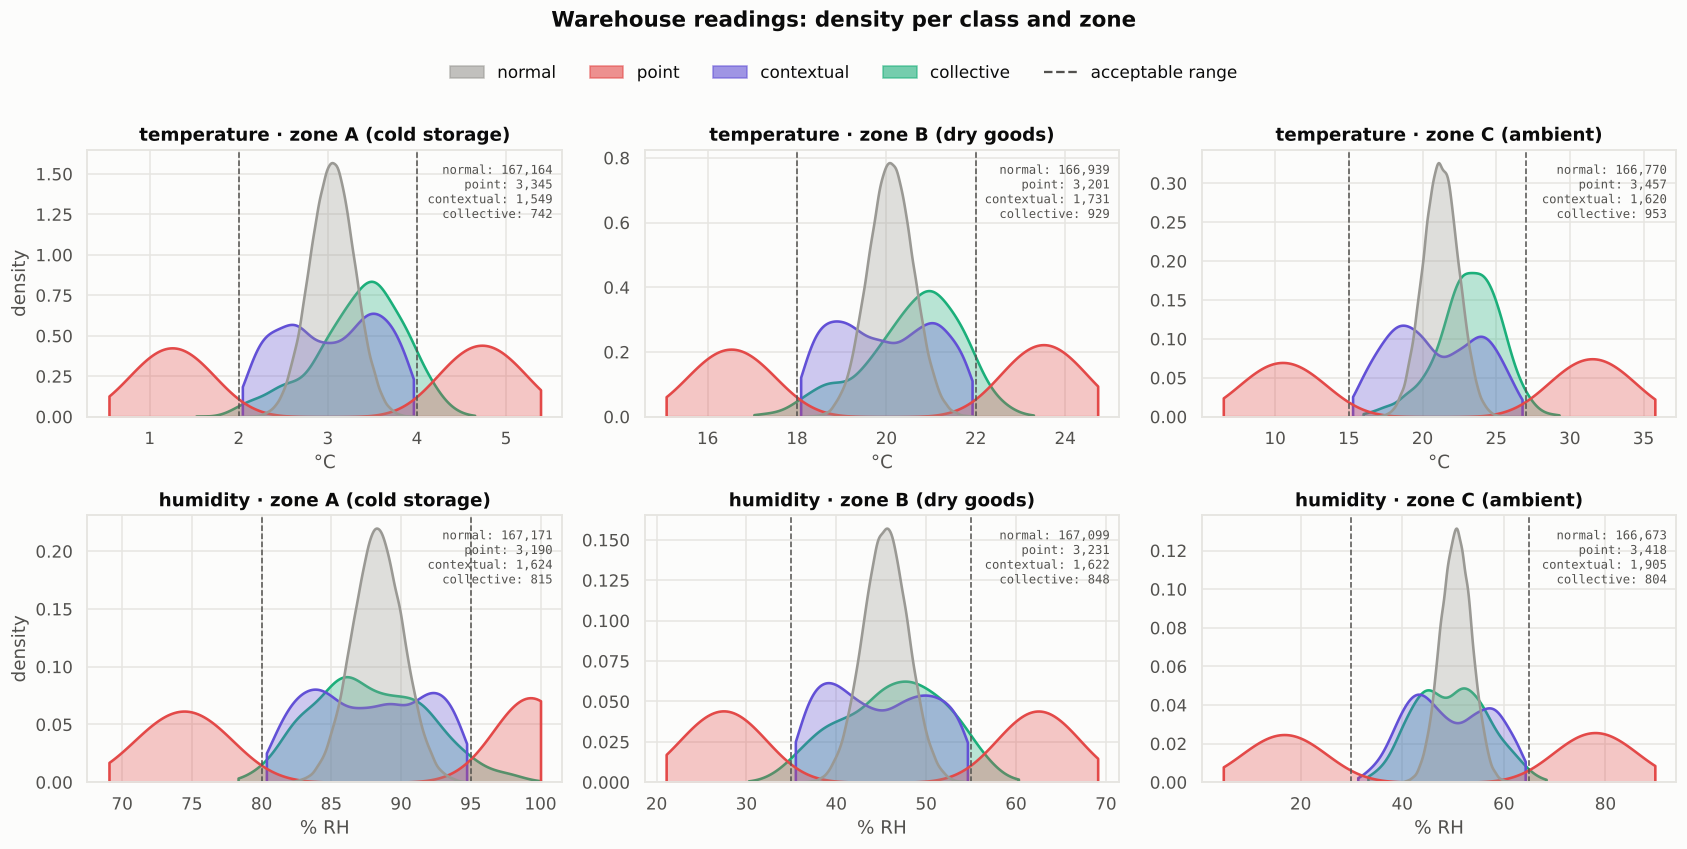

,flagged by a plain range check,rows
label,,
normal,0.0%,"1,001,816"
point,100.0%,"19,842"
contextual,0.0%,"10,051"
collective,5.5%,"5,091"


In [7]:
zones = list(cfg.simulation.warehouse.zones)
fig, axes = plt.subplots(2, len(zones), figsize=(15.5, 7.2))
for i, rt in enumerate(["temperature", "humidity"]):
    for j, z in enumerate(zones):
        ax = axes[i, j]
        sub = wh[(wh.reading_type == rt) & (wh.zone == z)]
        d = pd.concat([sub[~sub.is_anomaly].sample(min(60_000, int((~sub.is_anomaly).sum())), random_state=SEED),
                       sub[sub.is_anomaly]])
        sns.kdeplot(data=d, x="value", hue="label", hue_order=TYPES, palette=COL, common_norm=False, fill=True,
                    alpha=0.30, linewidth=1.7, ax=ax, legend=False, warn_singular=False, cut=0)
        lo, hi = sub.acc_lo.iloc[0], sub.acc_hi.iloc[0]
        ax.axvline(lo, ls="--", c=INK2, lw=1); ax.axvline(hi, ls="--", c=INK2, lw=1)
        n_by = sub.label.value_counts()
        ax.set_title(f"{rt} · zone {z} ({sub.storage_type.iloc[0].replace('_', ' ')})")
        ax.set_xlabel(sub.reading_type.map({"temperature": "°C", "humidity": "% RH"}).iloc[0]); ax.set_ylabel("density" if j == 0 else "")
        ax.text(0.98, 0.95, "\n".join(f"{t}: {n_by.get(t, 0):,}" for t in TYPES), transform=ax.transAxes, ha="right", va="top",
                fontsize=8, color=INK2, family="monospace")
fig.legend(handles=[Patch(color=COL[t], alpha=0.6, label=t) for t in TYPES] + [plt.Line2D([], [], ls="--", c=INK2, label="acceptable range")],
           loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Warehouse readings: density per class and zone", y=1.07, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

# How much of each class does a plain range check catch?
wh["in_range"] = wh.value.between(wh.acc_lo, wh.acc_hi)
range_tbl = (wh.groupby("label").in_range.agg(lambda s: 1 - s.mean()).rename("flagged by a plain range check").to_frame()
             .join(wh.label.value_counts().rename("rows")))
display(range_tbl.loc[TYPES].style.format({"flagged by a plain range check": "{:.1%}", "rows": "{:,.0f}"}))

### 2.2 Time-series view of the three anomaly patterns
One representative temperature sensor episode per type (median-length example). Grey band = acceptable range; markers repeat the type colour with distinct shapes.

In [8]:
wh_idx = {s: g.set_index("ts")[["value", "is_anomaly", "label", "acc_lo", "acc_hi", "episode_id"]] for s, g in wh.groupby("sensor_id")}

ep = (wh[wh.is_anomaly].groupby(["sensor_id", "episode_id"])
      .agg(type=("label", "first"), start=("ts", "min"), end=("ts", "max"), n=("ts", "size")).reset_index())
ep["hour"] = ep.start.dt.hour
wh_ep = ep.copy()

def pick(t: str, temp_only: bool = True) -> pd.Series:
    c = ep[(ep.type == t) & (ep.sensor_id.str.contains("temp") if temp_only else True)]
    if t == "contextual":
        c = c[c.hour < 5]
    return c.loc[(c.n - c.n.median()).abs().sort_values().index[0]]

examples = {t: pick(t) for t in ["point", "contextual", "collective"]}
fig = make_subplots(rows=3, cols=1, vertical_spacing=0.10,
                    subplot_titles=[f"{t} · {e.sensor_id} · {e.n} readings from {e.start:%H:%M:%S}" for t, e in examples.items()])
for r, (t, e) in enumerate(examples.items(), start=1):
    pad = pd.Timedelta(seconds=max(60, 3 * int(e.n)))
    w = wh_idx[e.sensor_id].loc[e.start - pad: e.end + pad]
    fig.add_hrect(y0=w.acc_lo.iloc[0], y1=w.acc_hi.iloc[0], fillcolor=COL["normal"], opacity=0.14, line_width=0, row=r, col=1)
    fig.add_scatter(x=w.index, y=w.value, mode="lines", line=dict(color=BLUE, width=1.4), name="reading", showlegend=(r == 1), row=r, col=1)
    a = w[w.is_anomaly]
    fig.add_scatter(x=a.index, y=a.value, mode="markers", marker=dict(color=COL[t], size=8, symbol=SYM[t], line=dict(color=SURFACE, width=1)),
                    name=f"{t} anomaly", row=r, col=1)
    fig.update_yaxes(title_text="°C", row=r, col=1)
fig.update_layout(title="Anomaly patterns in the raw signal (temperature sensors)")
show(fig, 860)

# 24-hour overview of one cold-storage sensor with all labelled anomalies
sid = "wh1-A-temp-01"
s24 = wh_idx[sid]
stride = s24.iloc[::10]
roll = s24.value.rolling("300s").mean().iloc[::10]
fig = go.Figure()
fig.add_vrect(x0=s24.index[0], x1=s24.index[0] + pd.Timedelta(hours=5), fillcolor=COL["contextual"], opacity=0.07, line_width=0)
fig.add_scatter(x=stride.index, y=stride.value, mode="lines", line=dict(color=BLUE, width=0.8), opacity=0.5, name="reading (every 10th)")
fig.add_scatter(x=roll.index, y=roll.values, mode="lines", line=dict(color=INK, width=1.8), name="5-min rolling mean")
for t in ["point", "contextual", "collective"]:
    a = s24[s24.label == t]
    fig.add_scatter(x=a.index, y=a.value, mode="markers", marker=dict(color=COL[t], size=5, symbol=SYM[t]), name=f"{t} ({len(a):,} rows)")
fig.add_hline(y=s24.acc_lo.iloc[0], line=dict(color=INK2, dash="dash", width=1)); fig.add_hline(y=s24.acc_hi.iloc[0], line=dict(color=INK2, dash="dash", width=1))
fig.add_annotation(x=s24.index[0] + pd.Timedelta(hours=2.5), y=1.0, yref="paper", text="off-hours", showarrow=False, yanchor="bottom", font=dict(color=COL["contextual"]))
fig.update_layout(title=f"{sid}: 24 h with ground-truth anomalies", yaxis_title="°C")
show(fig, 440)

### 2.3 Time-of-day structure (what makes the *contextual* anomaly contextual)

In [9]:
# Level of NORMAL readings per hour, standardised per sensor -> the diurnal pattern a context-aware model must learn
norm = wh[~wh.is_anomaly].copy()
g = norm.groupby("sensor_id").value
norm["z"] = (norm.value - g.transform("mean")) / g.transform("std")
diurnal = norm.groupby(["hour", "reading_type"]).z.mean().unstack()
share = wh.groupby(["hour", "label"]).size().unstack(fill_value=0).reindex(columns=TYPES, fill_value=0)
share = share.div(share.sum(axis=1), axis=0).mul(100)

fig = make_subplots(rows=1, cols=2, subplot_titles=("Share of readings that are anomalous, by hour (%)", "Mean standardised level of normal readings"),
                    horizontal_spacing=0.10)
for t in ["point", "contextual", "collective"]:
    fig.add_bar(x=share.index, y=share[t], name=t, marker_color=COL[t], marker_line=dict(color=SURFACE, width=2), row=1, col=1)
for rt, c in zip(["temperature", "humidity"], [BLUE, ORANGE]):
    fig.add_scatter(x=diurnal.index, y=diurnal[rt], name=f"normal {rt}", mode="lines+markers", line=dict(color=c, width=2),
                    marker=dict(size=6, line=dict(color=SURFACE, width=1)), row=1, col=2)
fig.update_layout(barmode="stack", title="Warehouse time-of-day structure")
fig.update_xaxes(title_text="hour of day (UTC)", dtick=2); fig.update_yaxes(title_text="% of readings", row=1, col=1); fig.update_yaxes(title_text="σ units", row=1, col=2)
show(fig, 440)
ctx_inside = wh[wh.label == "contextual"].in_range.mean()
print(f"{ctx_inside:.1%} of contextual readings sit INSIDE the acceptable range -> range / z-score-on-value baselines cannot see them;"
      f" they are only anomalous relative to the hour of day (hour_sin/hour_cos, level_shift, vol_ratio).")

100.0% of contextual readings sit INSIDE the acceptable range -> range / z-score-on-value baselines cannot see them; they are only anomalous relative to the hour of day (hour_sin/hour_cos, level_shift, vol_ratio).


### 2.4 Anomaly episode lengths
Episode length drives the LSTM lookback: a sequence model must see a whole episode *plus* some normal context to recognise a drift.

In [10]:
ep_stats = wh_ep.groupby("type").n.describe(percentiles=[.5, .9, .95, .99]).round(1)
display(ep_stats)
fig = go.Figure()
for t in ["point", "contextual", "collective"]:
    d = wh_ep[wh_ep.type == t]
    fig.add_histogram(x=d.n, name=f"{t} (n={len(d):,} episodes)", marker_color=COL[t], marker_line=dict(color=SURFACE, width=1.5), opacity=0.85,
                      xbins=dict(size=1), histnorm="probability")
fig.update_layout(barmode="overlay", title="Warehouse anomaly episode length (readings = seconds), share of each type's episodes",
                  xaxis_title="episode length (readings)", yaxis=dict(title="share of episodes", tickformat=".0%"))
show(fig, 400)

,count,mean,std,min,50%,90%,95%,99%,max
type,,,,,,,,,
collective,257.0000,19.8000,5.7000,10.0000,20.0000,27.0000,29.0000,30.0000,30.0000
contextual,"1,555.0000",6.5000,2.3000,3.0000,6.0000,10.0000,10.0000,10.0000,10.0000
point,"6,696.0000",3.0000,1.4000,1.0000,3.0000,5.0000,5.0000,5.0000,5.0000


### 2.5 Autocorrelation (ACF / PACF) — how long does each signal "remember"?

ACF/PACF are computed **per entity** (12 sensors, 5 vehicles, 50 SKUs) and averaged; the band is min–max across entities. Two variants:

* **all readings** (what a deployed model sees, anomalies included) — bars;
* **normal readings only** (anomalies dropped; reflects the background process) — line.

The practical memory threshold is **|ρ| ≥ 0.1**. The statistical 95 % band (≈ ±1.96/√N) is shown too, but with N ≈ 86 400 it is ±0.007 and flags even trivial correlations, so it is not a useful lookback criterion. *One step = one event of that entity* (1 s warehouse, 10 s GPS, irregular inventory), which is also what `SequenceBuilder` steps over.

In [11]:
from statsmodels.tsa.stattools import acf, pacf

def profile(series: list[np.ndarray], nlags: int, partial: bool) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    out = []
    for x in series:
        x = np.asarray(x, float)
        x = x[np.isfinite(x)]
        if len(x) > 4 * nlags and x.std() > 0:
            out.append(pacf(x, nlags=nlags, method="ywm") if partial else acf(x, nlags=nlags, fft=True))
    A = np.vstack(out)
    return A.mean(0), A.min(0), A.max(0)

def per_entity(df: pd.DataFrame, key: str, col: str, mask_normal: bool, sel=None) -> list[np.ndarray]:
    out = []
    for k, g in df.groupby(key):
        if sel is not None and not sel(k, g):
            continue
        g = g.sort_values("ts")
        out.append((g.loc[~g.is_anomaly, col] if mask_normal else g[col]).to_numpy())
    return out

ACF_SPECS = [  # (source, signal label, dataframe, entity key, column, selector, acf lags, pacf lags)
    ("warehouse", "temperature", wh, "sensor_id", "value", lambda k, g: g.reading_type.iloc[0] == "temperature", 120, 60),
    ("warehouse", "humidity", wh, "sensor_id", "value", lambda k, g: g.reading_type.iloc[0] == "humidity", 120, 60),
    ("vehicle", "speed_kmh", gps, "vehicle_id", "speed", None, 60, 30),
    ("vehicle", "route_adherence", gps, "vehicle_id", "adherence", None, 60, 30),
    ("inventory", "change_amount", inv, "sku_id", "chg", None, 60, 30),
    ("inventory", "new_level", inv, "sku_id", "new", None, 60, 30),
]
acf_res, rows = {}, []
for src, sig, df, key, col, sel, na, npa in ACF_SPECS:
    r = {}
    for variant, mask in [("all", False), ("normal", True)]:
        ser = per_entity(df, key, col, mask, sel)
        r[("acf", variant)] = profile(ser, na, False)
        r[("pacf", variant)] = profile(ser, npa, True)
        r["N"] = int(np.median([len(s) for s in ser]))
    acf_res[(src, sig)] = r
    for variant in ["all", "normal"]:
        a = r[("acf", variant)][0]; p = r[("pacf", variant)][0]
        below = np.flatnonzero(np.abs(a[1:]) < 0.1)
        memory = int(below[0] + 1) if len(below) else na
        sig_p = np.flatnonzero(np.abs(p[1:]) >= 0.1)
        rows.append({"source": src, "signal": sig, "variant": variant, "median N": r["N"], "95% band": 1.96 / math.sqrt(r["N"]),
                     "ACF(1)": a[1], "ACF(10)": a[10], "ACF(30)": a[30],
                     "memory lag (first |ACF|<0.1)": memory, "PACF order (last |PACF|≥0.1)": int(sig_p[-1] + 1) if len(sig_p) else 0})
acf_summary = pd.DataFrame(rows)
display(acf_summary.style.format({"95% band": "{:.4f}", "ACF(1)": "{:.3f}", "ACF(10)": "{:.3f}", "ACF(30)": "{:.3f}"}).hide(axis="index"))

acf_titles = [f"{src} · {sig} — {kind}" for (src, sig, *_rest) in ACF_SPECS for kind in ("ACF", "PACF")]
fig = make_subplots(rows=3, cols=4, vertical_spacing=0.11, horizontal_spacing=0.06, subplot_titles=acf_titles)
for k, (src, sig, df, key, col, sel, na, npa) in enumerate(ACF_SPECS):
    r, c0 = k // 2 + 1, (k % 2) * 2 + 1
    for kind_i, kind in enumerate(["acf", "pacf"]):
        c = c0 + kind_i
        am, alo, ahi = acf_res[(src, sig)][(kind, "all")]
        nm, _, _ = acf_res[(src, sig)][(kind, "normal")]
        lags = np.arange(len(am))
        fig.add_bar(x=lags[1:], y=am[1:], marker_color=BLUE, marker_line_width=0, name="all readings", showlegend=(k == 0 and kind_i == 0),
                    width=0.55, row=r, col=c)
        fig.add_scatter(x=lags[1:], y=nm[1:], mode="lines", line=dict(color=ORANGE, width=1.8), name="normal only", showlegend=(k == 0 and kind_i == 0), row=r, col=c)
        fig.add_hline(y=0.1, line=dict(color=INK2, width=1, dash="dot"), row=r, col=c)
        fig.add_hline(y=-0.1, line=dict(color=INK2, width=1, dash="dot"), row=r, col=c)
        fig.update_yaxes(range=[-0.35, 1.02], row=r, col=c, title_text="ρ" if c == 1 else None)
        fig.update_xaxes(title_text="lag (events)" if r == 3 else None, row=r, col=c)
fig.update_annotations(font_size=12)
fig.update_layout(title="Mean ACF / PACF across entities (dotted = ±0.1 practical-memory threshold)")
show(fig, 860)

source,signal,variant,median N,95% band,ACF(1),ACF(10),ACF(30),memory lag (first |ACF|<0.1),PACF order (last |PACF|≥0.1)
warehouse,temperature,all,83471,0.0068,0.372,0.015,0.011,4,2
warehouse,temperature,normal,83471,0.0068,0.025,0.026,0.022,1,0
warehouse,humidity,all,83529,0.0068,0.382,0.010,0.011,4,2
warehouse,humidity,normal,83529,0.0068,0.022,0.023,0.023,1,0
vehicle,speed_kmh,all,8466,0.0213,0.415,0.018,-0.003,5,2
vehicle,speed_kmh,normal,8466,0.0213,-0.006,-0.003,-0.000,1,0
vehicle,route_adherence,all,8466,0.0213,0.860,0.039,0.002,9,1
vehicle,route_adherence,normal,8466,0.0213,-0.008,0.008,0.001,1,0
inventory,change_amount,all,4285,0.0299,-0.070,-0.028,-0.005,1,0
inventory,change_amount,normal,4285,0.0299,-0.061,-0.027,-0.005,1,0


---
## 3 · GPS vehicle EDA

Five vehicles ping-pong on five freight corridors (Rotterdam–Brussels, Chicago–Indianapolis, Los Angeles–San Diego, Frankfurt–Munich, Atlanta–Savannah) every 10 s. Anomalies: **route_deviation** (> 500 m off the corridor), **sudden_stop / excessive_speed** (point), **gradual_delay** (collective: speed decays over 12–30 readings).

### 3.1 Route visualisation (latitude vs longitude), anomalies in red
Marker shape encodes the anomaly sub-type. Deviations are 0.5–1.5 km, invisible at corridor scale, so §3.1b zooms in on one.

In [12]:
SUB_SYM = {"route_deviation": "diamond", "sudden_stop": "x", "excessive_speed": "triangle-up", "gradual_delay": "square"}
routes = list(dict.fromkeys(v.route_id for v in VEHICLES.values()))
fig = make_subplots(rows=2, cols=3, subplot_titles=[f"{r} ({next(v.origin for v in VEHICLES.values() if v.route_id == r)} → {next(v.destination for v in VEHICLES.values() if v.route_id == r)})" for r in routes],
                    horizontal_spacing=0.07, vertical_spacing=0.14)
for k, rid in enumerate(routes):
    r, c = k // 3 + 1, k % 3 + 1
    veh = next(v for v in VEHICLES.values() if v.route_id == rid)
    g = gps[gps.route_id == rid]
    n = g[~g.is_anomaly].iloc[::4]
    wp = np.array(veh.waypoints)
    fig.add_scatter(x=wp[:, 1], y=wp[:, 0], mode="lines", line=dict(color=INK2, width=1, dash="dot"), name="planned route", showlegend=(k == 0), row=r, col=c)
    fig.add_scatter(x=n.lon, y=n.lat, mode="markers", marker=dict(color="#b9b8b2", size=4), name="normal (every 4th)", showlegend=(k == 0), row=r, col=c)
    for sub, sym in SUB_SYM.items():
        a = g[g.subtype == sub]
        fig.add_scatter(x=a.lon, y=a.lat, mode="markers", marker=dict(color=COL["point"], size=7, symbol=sym, opacity=0.85),
                        name=sub, showlegend=(k == 0), legendgroup=sub, row=r, col=c)
    fig.update_xaxes(title_text="longitude" if r == 2 else None, row=r, col=c); fig.update_yaxes(title_text="latitude" if c == 1 else None, row=r, col=c)
fig.update_layout(title="GPS tracks per corridor — anomalies in red, shape = sub-type")
show(fig, 760)

**3.1b Close-up of the longest route deviation** — points sit ≥ 500 m from the planned corridor, while the vehicle's speed stays normal.

In [13]:
dev = gps[gps.subtype == "route_deviation"].groupby(["vehicle_id", "episode_id"]).agg(n=("ts", "size"), start=("ts", "min"), end=("ts", "max")).reset_index()
e = dev.sort_values("n", ascending=False).iloc[0]
g = gps[(gps.vehicle_id == e.vehicle_id) & (gps.ts >= e.start - pd.Timedelta(minutes=4)) & (gps.ts <= e.end + pd.Timedelta(minutes=4))]
veh = VEHICLES[e.vehicle_id]
wp = np.array(veh.waypoints)
fig = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45], subplot_titles=(f"{e.vehicle_id}: {e.n} deviating readings (zoomed)", "distance from route & speed vs time"),
                    specs=[[{}, {"secondary_y": True}]])
fig.add_scatter(x=wp[:, 1], y=wp[:, 0], mode="lines", line=dict(color=INK2, width=2, dash="dot"), name="planned route", row=1, col=1)
fig.add_scatter(x=g[~g.is_anomaly].lon, y=g[~g.is_anomaly].lat, mode="markers", marker=dict(color=COL["normal"], size=7), name="normal", row=1, col=1)
fig.add_scatter(x=g[g.is_anomaly].lon, y=g[g.is_anomaly].lat, mode="markers", marker=dict(color=COL["point"], size=9, symbol="diamond", line=dict(color=SURFACE, width=1)), name="route_deviation", row=1, col=1)
pad_lon, pad_lat = 0.02, 0.012
fig.update_xaxes(range=[g.lon.min() - pad_lon, g.lon.max() + pad_lon], title_text="longitude", row=1, col=1)
fig.update_yaxes(range=[g.lat.min() - pad_lat, g.lat.max() + pad_lat], title_text="latitude", row=1, col=1)
fig.add_scatter(x=g.ts, y=g.dist_m, mode="lines+markers", line=dict(color=BLUE, width=1.6), marker=dict(size=5), name="distance from route (m)", row=1, col=2, secondary_y=False)
fig.add_hline(y=cfg.simulation.vehicle.route_deviation_m, line=dict(color=COL["point"], dash="dash", width=1), row=1, col=2, secondary_y=False)
fig.add_scatter(x=g.ts, y=g.speed, mode="lines", line=dict(color=ORANGE, width=1.4), name="speed (km/h)", row=1, col=2, secondary_y=True)
fig.update_yaxes(title_text="m from corridor centre-line", row=1, col=2, secondary_y=False)
fig.update_yaxes(title_text="speed (km/h)", tickformat=".0f", showgrid=False, row=1, col=2, secondary_y=True)
show(fig, 460)

### 3.2 Speed distribution and anomaly speed patterns
Speed is expressed as a ratio to the vehicle's own cruising speed so the five vehicles are comparable (normal band is 0.6–1.2×). One panel per anomaly sub-type, against the normal distribution (grey).

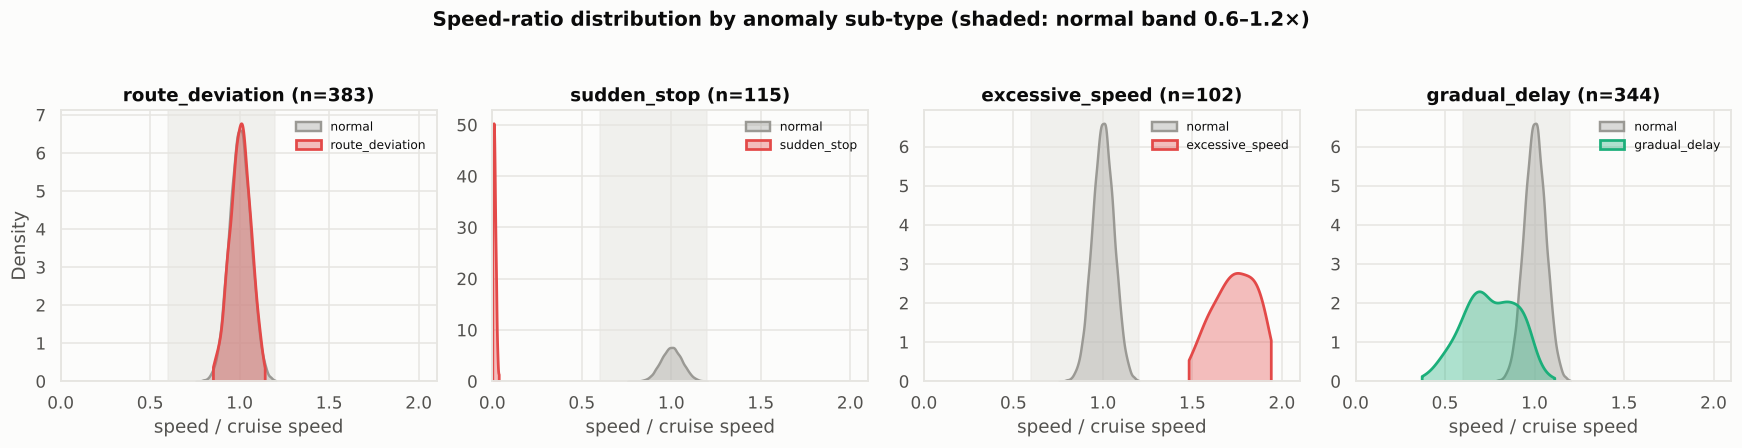

route_deviation readings have speed ratio 1.00 (median) — 100% inside the normal speed band: speed alone cannot detect deviations, route_adherence_score / distance can.


In [14]:
subs = ["route_deviation", "sudden_stop", "excessive_speed", "gradual_delay"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9), sharey=False)
nrm = gps[~gps.is_anomaly].sample(30_000, random_state=SEED)
for ax, sub in zip(axes, subs):
    a = gps[gps.subtype == sub]
    c = COL["collective"] if sub == "gradual_delay" else COL["point"]
    sns.kdeplot(nrm.speed_ratio, ax=ax, color=COL["normal"], fill=True, alpha=0.35, linewidth=1.6, cut=0, label="normal")
    sns.kdeplot(a.speed_ratio, ax=ax, color=c, fill=True, alpha=0.35, linewidth=1.8, cut=0, warn_singular=False, label=sub)
    ax.axvspan(0.6, 1.2, color=GRID, alpha=0.5, zorder=0)
    ax.set_title(f"{sub} (n={len(a):,})"); ax.set_xlabel("speed / cruise speed"); ax.set_xlim(0, 2.1)
    ax.legend(frameon=False, fontsize=8)
for ax in axes[1:]:
    ax.set_ylabel("")
fig.suptitle("Speed-ratio distribution by anomaly sub-type (shaded: normal band 0.6–1.2×)", y=1.04, fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

# Speed time series: a gradual delay and a stop/excessive-speed episode
def ep_window(sub, vehicle=None):
    d = gps[gps.subtype == sub].groupby(["vehicle_id", "episode_id"]).agg(n=("ts", "size"), start=("ts", "min"), end=("ts", "max")).reset_index()
    return d.sort_values("n", ascending=False).iloc[0]

fig = make_subplots(rows=2, cols=1, vertical_spacing=0.14, subplot_titles=("gradual_delay (collective): speed decays smoothly", "sudden_stop / excessive_speed (point)"))
for r, subs_ in enumerate([["gradual_delay"], ["sudden_stop", "excessive_speed"]], start=1):
    e = ep_window(subs_[0])
    g = gps[(gps.vehicle_id == e.vehicle_id) & (gps.ts >= e.start - pd.Timedelta(minutes=6)) & (gps.ts <= e.end + pd.Timedelta(minutes=6))]
    cr = g.cruise.iloc[0]
    fig.add_hrect(y0=0.6 * cr, y1=1.2 * cr, fillcolor=COL["normal"], opacity=0.14, line_width=0, row=r, col=1)
    fig.add_scatter(x=g.ts, y=g.speed, mode="lines", line=dict(color=BLUE, width=1.5), name=f"{e.vehicle_id} speed", showlegend=(r == 1), row=r, col=1)
    for sub in subs_:
        a = g[g.subtype == sub]
        c = COL["collective"] if sub == "gradual_delay" else COL["point"]
        fig.add_scatter(x=a.ts, y=a.speed, mode="markers", marker=dict(color=c, size=8, symbol=SUB_SYM[sub], line=dict(color=SURFACE, width=1)), name=sub, row=r, col=1)
    fig.update_yaxes(title_text="km/h", row=r, col=1)
fig.update_layout(title="Speed anomalies in the raw signal (grey band: normal 0.6–1.2× cruise)")
show(fig, 640)

dev_speed = gps[gps.subtype == "route_deviation"].speed_ratio
print(f"route_deviation readings have speed ratio {dev_speed.median():.2f} (median) — {dev_speed.between(0.6, 1.2).mean():.0%} inside the normal speed band: "
      f"speed alone cannot detect deviations, route_adherence_score / distance can.")

### 3.3 Route-adherence heat-map over time
Each cell is the **worst** (minimum) `route_adherence_score` of a vehicle within a 5-minute bin, shown as the *adherence deficit* `1 − min score` (dark = the vehicle left the corridor in that bin). Normal GPS noise keeps the deficit near zero.

In [15]:
gps["bin"] = gps.ts.dt.floor("5min")
deficit = (1 - gps.groupby(["vehicle_id", "bin"]).adherence.min()).unstack(0).T
route_of = {v.vehicle_id: v.route_id for v in VEHICLES.values()}
fig = go.Figure(go.Heatmap(z=deficit.values, x=deficit.columns, y=[f"{v} · {route_of[v]}" for v in deficit.index],
                           colorscale=[[i / (len(SEQ) - 1), c] for i, c in enumerate(SEQ)], zmin=0, zmax=0.8,
                           colorbar=dict(title="1 − min<br>adherence", thickness=12), xgap=1, ygap=2,
                           hovertemplate="%{y}<br>%{x|%H:%M}<br>deficit %{z:.2f}<extra></extra>"))
fig.update_layout(title="Route-adherence deficit per vehicle (5-min bins)", xaxis_title="time (UTC)", yaxis=dict(autorange="reversed"),
                  margin=dict(t=84, l=150))
show(fig, 380)
bad = gps[gps.subtype == "route_deviation"]
print(f"adherence score of route_deviation readings: median {bad.adherence.median():.2f}, max {bad.adherence.max():.2f}   |   "
      f"normal readings: min {gps[~gps.is_anomaly].adherence.min():.2f}, median {gps[~gps.is_anomaly].adherence.median():.3f}")

adherence score of route_deviation readings: median 0.05, max 0.14   |   normal readings: min 1.00, median 1.000


---
## 4 · Inventory EDA

Normal stock follows a saw-tooth (small shipments drain it, a lot-sized restock tops it up at the reorder point). **sudden_drop** (point) is a large unexplained decrease booked as an `adjustment`; **ghost_stock** (contextual) is stock appearing as a `restock` while the level is nowhere near the reorder point.

### 4.1 Stock-level time series with anomaly events

In [16]:
cnt = inv[inv.is_anomaly].groupby(["sku_id", "subtype"]).size().unstack(fill_value=0)
# one SKU per panel; the window is centred on the median-time event of the shown sub-type
picks = [(cnt.sort_values("sudden_drop", ascending=False).index[0], "sudden_drop"), (cnt.sort_values("sudden_drop", ascending=False).index[1], "sudden_drop"),
         (cnt.sort_values("ghost_stock", ascending=False).index[0], "ghost_stock"), (cnt.sort_values("ghost_stock", ascending=False).index[1], "ghost_stock")]
HALF = pd.Timedelta(minutes=25)
wins = []
for sku, sub in picks:
    a_ = inv[(inv.sku_id == sku) & (inv.subtype == sub) & (inv.ts > inv.ts.min() + HALF) & (inv.ts < inv.ts.max() - HALF)].sort_values("ts")
    wins.append((sku, sub, a_.ts.iloc[len(a_) // 2]))
fig = make_subplots(rows=2, cols=2, subplot_titles=[f"{s} · {sub} at {t:%H:%M} · wh {ITEMS[s].warehouse_id}, zone {ITEMS[s].zone}, capacity {ITEMS[s].max_stock}" for s, sub, t in wins],
                    vertical_spacing=0.17, horizontal_spacing=0.08)
for k, (sku, _sub, t0_) in enumerate(wins):
    r, c = k // 2 + 1, k % 2 + 1
    g = inv[(inv.sku_id == sku) & (inv.ts >= t0_ - HALF) & (inv.ts <= t0_ + HALF)]
    it = ITEMS[sku]
    fig.add_scatter(x=g.ts, y=g.new, mode="lines", line=dict(color=BLUE, width=1.5, shape="hv"), name="stock level", showlegend=(k == 0), row=r, col=c)
    for sub_, t_ in [("sudden_drop", "point"), ("ghost_stock", "contextual")]:
        a_ = g[g.subtype == sub_]
        fig.add_scatter(x=a_.ts, y=a_.new, mode="markers", marker=dict(color=COL[t_], size=12, symbol=SYM[t_], line=dict(color=SURFACE, width=1)),
                        name=sub_, showlegend=((sub_ == "sudden_drop" and k == 0) or (sub_ == "ghost_stock" and k == 2)), legendgroup=sub_, row=r, col=c,
                        customdata=a_.chg, hovertemplate="%{x|%H:%M:%S}<br>level %{y}<br>change %{customdata:+d}<extra>" + sub_ + "</extra>")
    fig.add_hline(y=it.reorder_point, line=dict(color=ORANGE, dash="dash", width=1.2), row=r, col=c)
    fig.add_hline(y=it.min_stock, line=dict(color=INK2, dash="dot", width=1), row=r, col=c)
    fig.update_yaxes(title_text="units" if c == 1 else None, row=r, col=c)
fig.add_annotation(x=1.0, y=-0.07, xref="paper", yref="paper", text="orange dashed = reorder point · grey dotted = minimum stock", showarrow=False,
                   xanchor="right", yanchor="top", font=dict(size=11, color=INK2))
fig.update_layout(title="Stock level in 50-minute windows around anomalies — saw-tooth: shipments drain, restocks at the reorder point refill")
show(fig, 760)

### 4.2 Change-amount distribution and multi-sigma events
`change_amount` is the signed stock delta of an event. A first-instinct detector is "flag changes larger than *k* σ". We test that rule with a per-SKU **robust σ** (1.4826 × MAD of the SKU's own changes — no labels used) and see how far it gets.

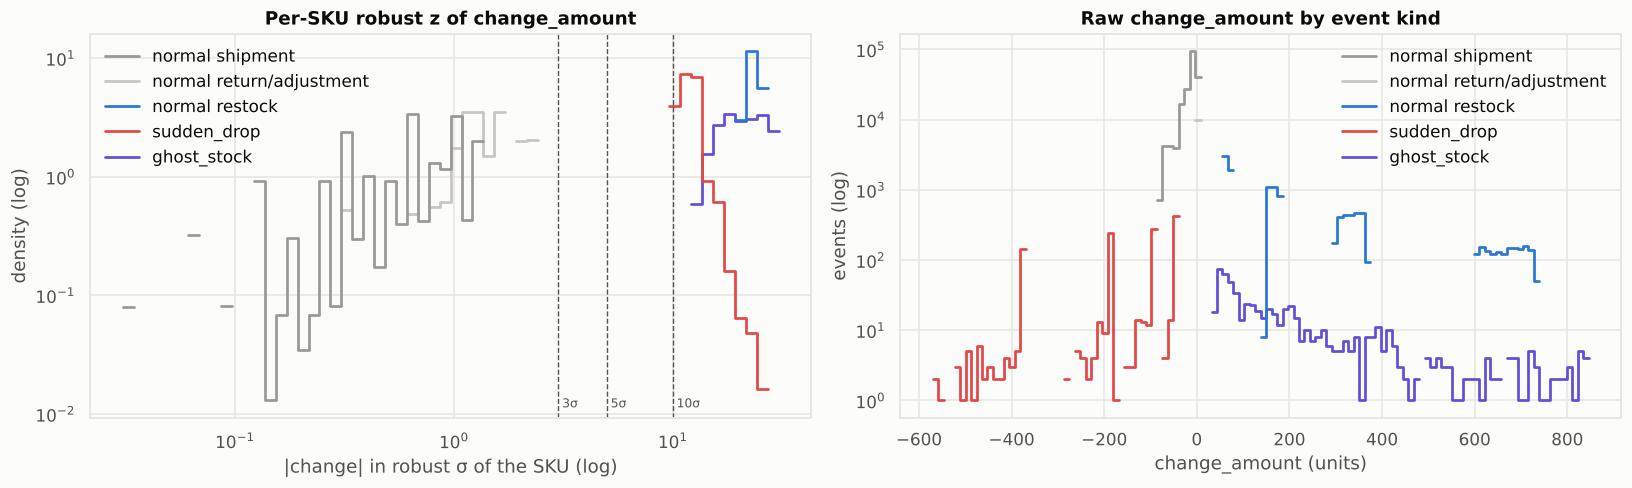

variant,k (σ),flagged,recall sudden_drop,recall ghost_stock,precision,false alarms that are normal restocks
per SKU,3,"13,950",100.0%,100.0%,13.5%,100.0%
per SKU,5,"13,950",100.0%,100.0%,13.5%,100.0%
per SKU,10,"13,950",100.0%,100.0%,13.5%,100.0%
per SKU,20,"12,010",0.4%,54.6%,3.0%,100.0%
per SKU,30,11,0.0%,1.7%,–,–
per SKU,50,0,0.0%,0.0%,–,–
per SKU x transaction type,3,"1,495",100.0%,38.9%,100.0%,–
per SKU x transaction type,5,"1,288",100.0%,7.0%,100.0%,–
per SKU x transaction type,10,933,75.1%,0.0%,100.0%,–
per SKU x transaction type,20,710,57.1%,0.0%,100.0%,–


**|change| in per-SKU robust σ, by event kind (5th / 50th / 95th percentile)**

,0.0500,0.5000,0.9500
kind,,,
normal shipment,0.0000,0.7000,1.3000
normal return/adjustment,0.7000,1.3000,2.4000
normal restock,20.4000,22.9000,25.6000
sudden_drop,10.5000,11.6000,14.8000
ghost_stock,14.3000,20.6000,28.8000


In [17]:
inv = inv.sort_values(["sku_id", "ts"]).reset_index(drop=True)
grp = inv.groupby("sku_id").chg
med = grp.transform("median")
mad = grp.transform(lambda s: (s - s.median()).abs().median())
sigma = (1.4826 * mad).where(mad > 0, grp.transform("std"))
inv["z"] = ((inv.chg - med).abs() / sigma)
g2 = inv.groupby(["sku_id", "ttype"]).chg
med2 = g2.transform("median")
mad2 = g2.transform(lambda s: (s - s.median()).abs().median())
inv["z_type"] = (inv.chg - med2).abs() / (1.4826 * mad2).clip(lower=1.0)  # judged against its own transaction type
inv["kind"] = np.select([inv.subtype == "sudden_drop", inv.subtype == "ghost_stock", inv.ttype == "restock", inv.ttype == "shipment"],
                        ["sudden_drop", "ghost_stock", "normal restock", "normal shipment"], "normal return/adjustment")
KIND_COL = {"normal shipment": COL["normal"], "normal return/adjustment": "#c7c6c1", "normal restock": BLUE, "sudden_drop": COL["point"], "ghost_stock": COL["contextual"]}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
sns.histplot(data=inv, x="z", hue="kind", hue_order=list(KIND_COL), palette=KIND_COL, log_scale=(True, True), element="step", stat="density",
             common_norm=False, fill=False, linewidth=1.8, bins=60, ax=axes[0])
axes[0].set_xlabel("|change| in robust σ of the SKU (log)"); axes[0].set_ylabel("density (log)"); axes[0].set_title("Per-SKU robust z of change_amount")
for k in (3, 5, 10):
    axes[0].axvline(k, ls="--", c=INK2, lw=0.9); axes[0].text(k * 1.04, 0.02, f"{k}σ", ha="left", va="bottom", fontsize=8, color=INK2, transform=axes[0].get_xaxis_transform())
sns.histplot(data=inv, x="chg", hue="kind", hue_order=list(KIND_COL), palette=KIND_COL, element="step", fill=False, linewidth=1.8, bins=120,
             common_norm=False, stat="count", ax=axes[1], log_scale=(False, True))
axes[1].set_xlabel("change_amount (units)"); axes[1].set_ylabel("events (log)"); axes[1].set_title("Raw change_amount by event kind")
for ax in axes:
    if ax.get_legend():
        ax.get_legend().set_title(None); ax.get_legend().set_frame_on(False)
plt.tight_layout(); plt.show()

LAD_K = (3, 5, 10, 20, 30, 50)
VARIANTS = [("per SKU", "z"), ("per SKU x transaction type", "z_type")]
ladder = []
for variant, zc in VARIANTS:
    for k in LAD_K:
        flag = inv[zc] > k
        fa = flag & ~inv.is_anomaly
        ladder.append({"variant": variant, "k (σ)": k, "flagged": int(flag.sum()), "recall sudden_drop": flag[inv.subtype == "sudden_drop"].mean(),
                       "recall ghost_stock": flag[inv.subtype == "ghost_stock"].mean(), "precision": inv.is_anomaly[flag].mean() if flag.sum() >= 20 else np.nan,
                       "false alarms that are normal restocks": (inv.kind[fa] == "normal restock").mean() if fa.any() else np.nan})
sigma_ladder = pd.DataFrame(ladder)
display(sigma_ladder.style.format({"recall sudden_drop": "{:.1%}", "recall ghost_stock": "{:.1%}", "precision": "{:.1%}",
                                   "false alarms that are normal restocks": "{:.1%}", "flagged": "{:,.0f}"}, na_rep="–").hide(axis="index"))
zq = inv.groupby("kind").z.quantile([0.05, 0.5, 0.95]).unstack().reindex(list(KIND_COL))
hdr("**|change| in per-SKU robust σ, by event kind (5th / 50th / 95th percentile)**")
display(zq.round(1))

fig = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.05,
                    subplot_titles=("σ estimated per SKU (all transaction types pooled)", "σ estimated per SKU × transaction type"))
for j, (variant, _) in enumerate(VARIANTS, start=1):
    d = sigma_ladder[sigma_ladder.variant == variant]
    for col, c, sym in [("recall sudden_drop", COL["point"], SYM["point"]), ("recall ghost_stock", COL["contextual"], SYM["contextual"]), ("precision", BLUE, "circle")]:
        fig.add_scatter(x=d["k (σ)"], y=d[col], mode="lines+markers", name=col, showlegend=(j == 1), line=dict(color=c, width=2, dash="dash" if col == "precision" else "solid"),
                        marker=dict(size=8, symbol=sym, line=dict(color=SURFACE, width=1)), row=1, col=j)
    fig.update_xaxes(title_text="threshold k (robust σ)", type="log", tickvals=list(LAD_K), row=1, col=j)
fig.update_layout(title="'Flag changes larger than kσ' as an inventory detector", yaxis=dict(tickformat=".0%", range=[0, 1.02]))
show(fig, 420)

### 4.3 Context separates ghost stock from a genuine restock
A ghost-stock event has exactly the size and booking type of a legitimate restock. What differs is the **context**: legitimate restocks happen when the level has fallen to the reorder point. `stock_vs_reorder = (previous_level − reorder_point) / (max − min)` is ≤ 0 for a genuine restock trigger.

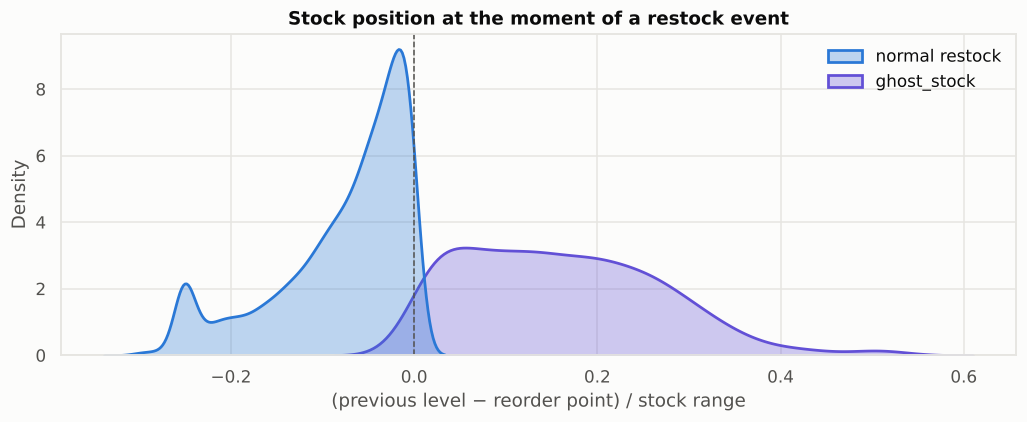

100.0% of ghost-stock events occur ABOVE the reorder point vs 0.0% of normal restocks (n ghost = 647, n restock = 12,060).


In [18]:
rs = inv[inv.ttype == "restock"].copy()
rs["svr"] = (rs.prev - rs.reorder_point) / (rs.max_stock - rs.min_stock)
rs["who"] = np.where(rs.is_anomaly, "ghost_stock", "normal restock")
fig, ax = plt.subplots(figsize=(9.5, 4))
sns.kdeplot(data=rs, x="svr", hue="who", hue_order=["normal restock", "ghost_stock"], palette={"normal restock": BLUE, "ghost_stock": COL["contextual"]},
            common_norm=False, fill=True, alpha=0.3, linewidth=1.8, ax=ax, warn_singular=False)
ax.axvline(0, ls="--", c=INK2, lw=1); ax.set_xlabel("(previous level − reorder point) / stock range"); ax.set_title("Stock position at the moment of a restock event")
ax.get_legend().set_title(None); ax.get_legend().set_frame_on(False)
plt.tight_layout(); plt.show()
ghost = rs[rs.is_anomaly]
print(f"{(ghost.svr > 0).mean():.1%} of ghost-stock events occur ABOVE the reorder point vs {(rs[~rs.is_anomaly].svr > 0).mean():.1%} of normal restocks "
      f"(n ghost = {len(ghost)}, n restock = {(~rs.is_anomaly).sum():,}).")

---
## 5 · Feature correlation, information content and separability

The matrices analysed here are the real Day 6 feature vectors (one row per event; 30 warehouse, 41 vehicle, 42 inventory features), computed from the 1/5/15-minute windows.

### 5.0 Which rows and features take part?

Three filters are applied, all justified by how the pipeline works:

* **Cold start** — rows with `warmup_ratio < 0.9` (the 15-minute window not yet filled) are excluded; early z-scores have no baseline.
* **Constant features** — columns with zero variance on the remaining rows carry no information. Offline they are expected for features that depend on *runtime feedback* (`time_since_last_anomaly_log`, `anomaly_rate_7d`, `reliability` need `EntityHistory` fed by detectors/analysts) and for calendar features that cannot vary inside one day (`dow_*`).
* **Entity hold-out for model-based checks** — the 24-hour sample holds all *contextual* anomalies in 00:00–05:00, so a chronological train/test split would leave the test set with none (shown below). Models in §5.4–5.6 therefore train on `wh1` / vehicles 001–003 / `wh1` SKUs and are tested on the unseen entities.

In [19]:
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

train_entities = {
    "warehouse": {e: e.startswith("wh1") for e in F["warehouse"].entity_id.unique()},
    "vehicle": {e: e in ("veh-001", "veh-002", "veh-003") for e in F["vehicle"].entity_id.unique()},
    "inventory": {e: ITEMS[e].warehouse_id == "wh1" for e in F["inventory"].entity_id.unique()},
}
PREP, rows = {}, []
for s in SOURCES:
    df, feats = F[s], FNAMES[s]
    warm = (df.warmup_ratio >= 0.9).to_numpy()
    sd = df.loc[warm, feats].std(skipna=True)
    const = [c for c in feats if not (sd[c] > 0)]
    keep = [c for c in feats if c not in const]
    PREP[s] = dict(warm=warm, const=const, keep=keep, train=df.entity_id.map(train_entities[s]).to_numpy(), y=df.is_anomaly.to_numpy())
    w = df[warm]
    rows.append({"source": s, "feature rows": len(df), "warm rows": int(warm.sum()), "% warm": 100 * warm.mean(),
                 "features": len(feats), "constant (dropped)": len(const), "kept": len(keep),
                 "anomaly rate (warm)": w.is_anomaly.mean(), "train rows": int((warm & PREP[s]["train"]).sum()), "test rows": int((warm & ~PREP[s]["train"]).sum())})
display(pd.DataFrame(rows).style.format({"feature rows": "{:,.0f}", "warm rows": "{:,.0f}", "% warm": "{:.1f}", "anomaly rate (warm)": "{:.2%}",
                                          "train rows": "{:,.0f}", "test rows": "{:,.0f}"}).hide(axis="index"))
for s in SOURCES:
    print(f"{s:10s} constant features: {PREP[s]['const']}")

split_ts = pd.Timestamp("2026-11-20 16:15", tz="UTC")
ts_test = F["warehouse"].ts >= split_ts
chrono = F["warehouse"][PREP["warehouse"]["warm"]].assign(test=ts_test[PREP["warehouse"]["warm"]]).groupby(["label", "test"]).size().unstack(fill_value=0)
chrono.columns = ["train (< 16:15)", "test (≥ 16:15)"]
print("\nWhy not a chronological split? Warehouse anomalies per class on each side of 16:15:")
display(chrono.loc[[t for t in TYPES if t in chrono.index]])

source,feature rows,warm rows,% warm,features,constant (dropped),kept,anomaly rate (warm),train rows,test rows
warehouse,"1,036,800","1,027,080",99.1,30,6,24,3.34%,"513,540","513,540"
vehicle,"43,200","42,795",99.1,41,6,35,2.19%,"25,677","17,118"
inventory,"216,098","212,753",98.5,42,5,37,0.88%,"106,255","106,498"


warehouse  constant features: ['time_since_last_anomaly_log', 'log_count_short', 'dow_sin', 'dow_cos', 'anomaly_rate_7d', 'reliability']
vehicle    constant features: ['time_since_last_anomaly_log', 'log_count_short', 'dow_sin', 'dow_cos', 'anomaly_rate_7d', 'reliability']
inventory  constant features: ['time_since_last_anomaly_log', 'dow_sin', 'dow_cos', 'anomaly_rate_7d', 'reliability']

Why not a chronological split? Warehouse anomalies per class on each side of 16:15:


,train (< 16:15),test (≥ 16:15)
label,,
normal,666468,326258
point,12992,6687
contextual,9643,0
collective,3177,1855


### 5.1 Correlation heat-maps across all engineered features
Spearman rank correlation on a 60 k random sample of warm rows; features are ordered by hierarchical clustering (distance 1 − |ρ|) so redundant groups appear as blocks. Blue = positive, orange = negative.

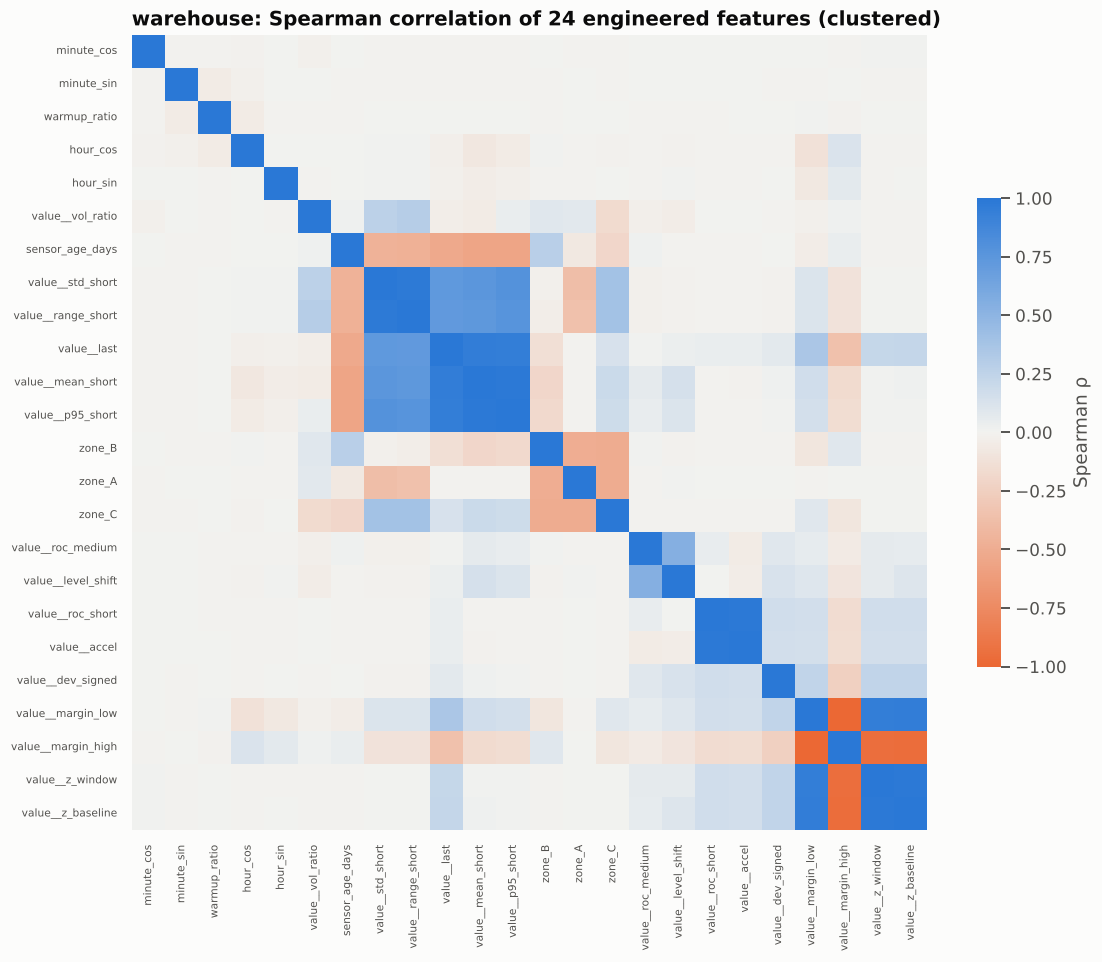

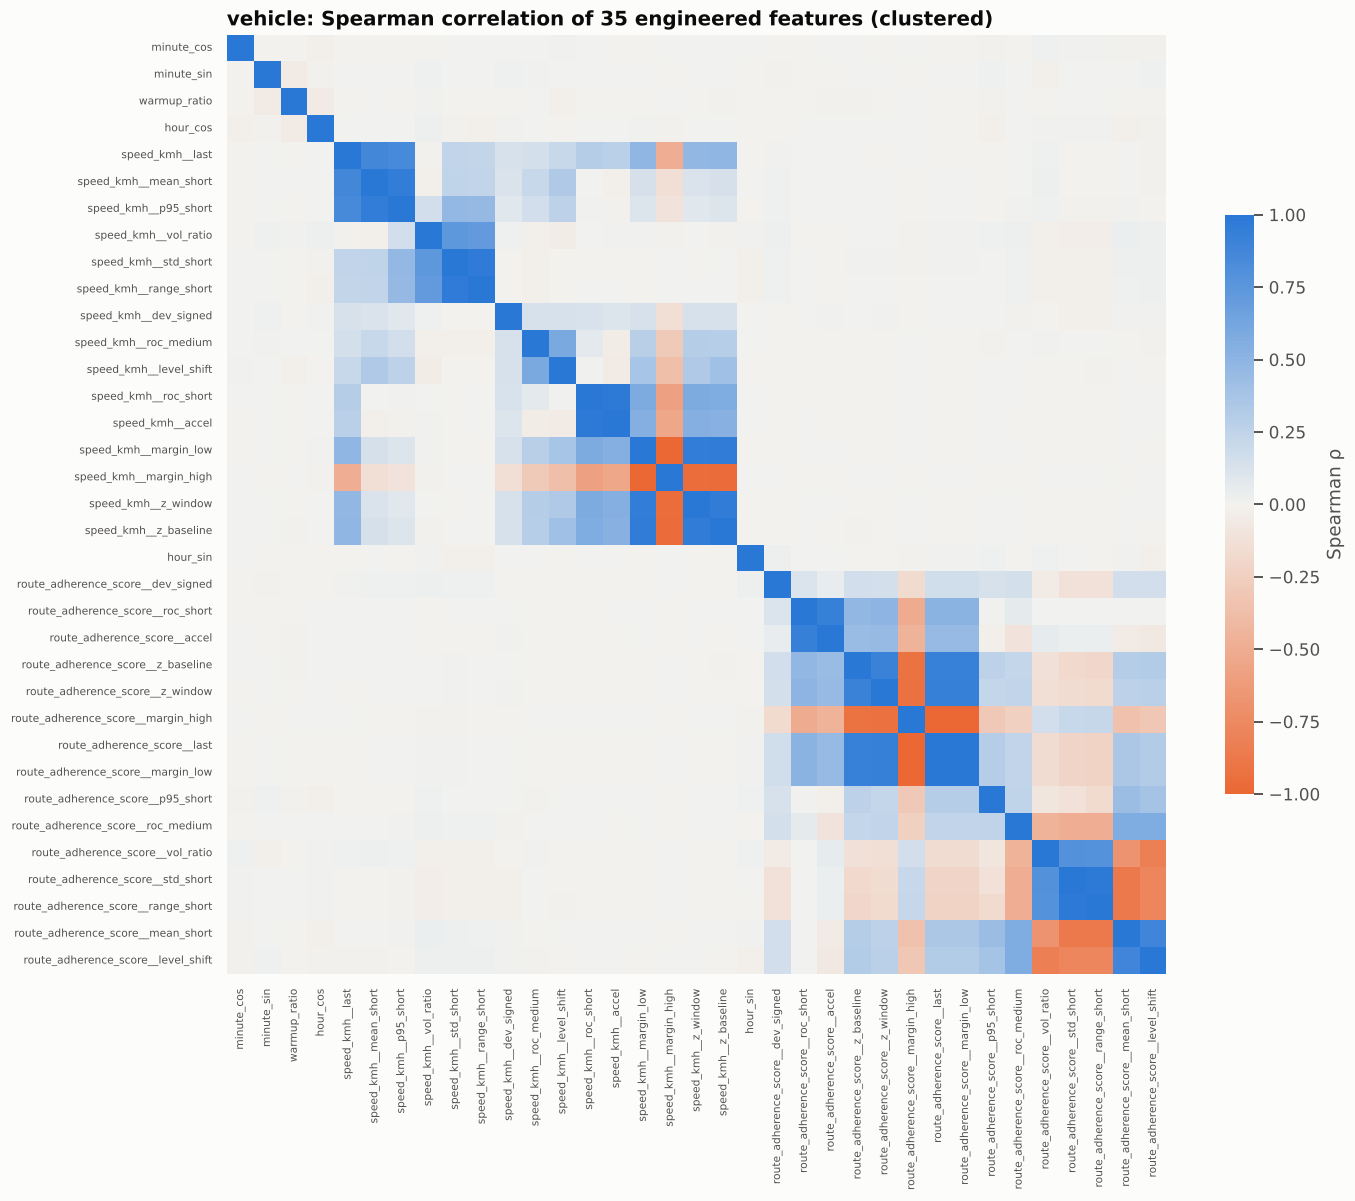

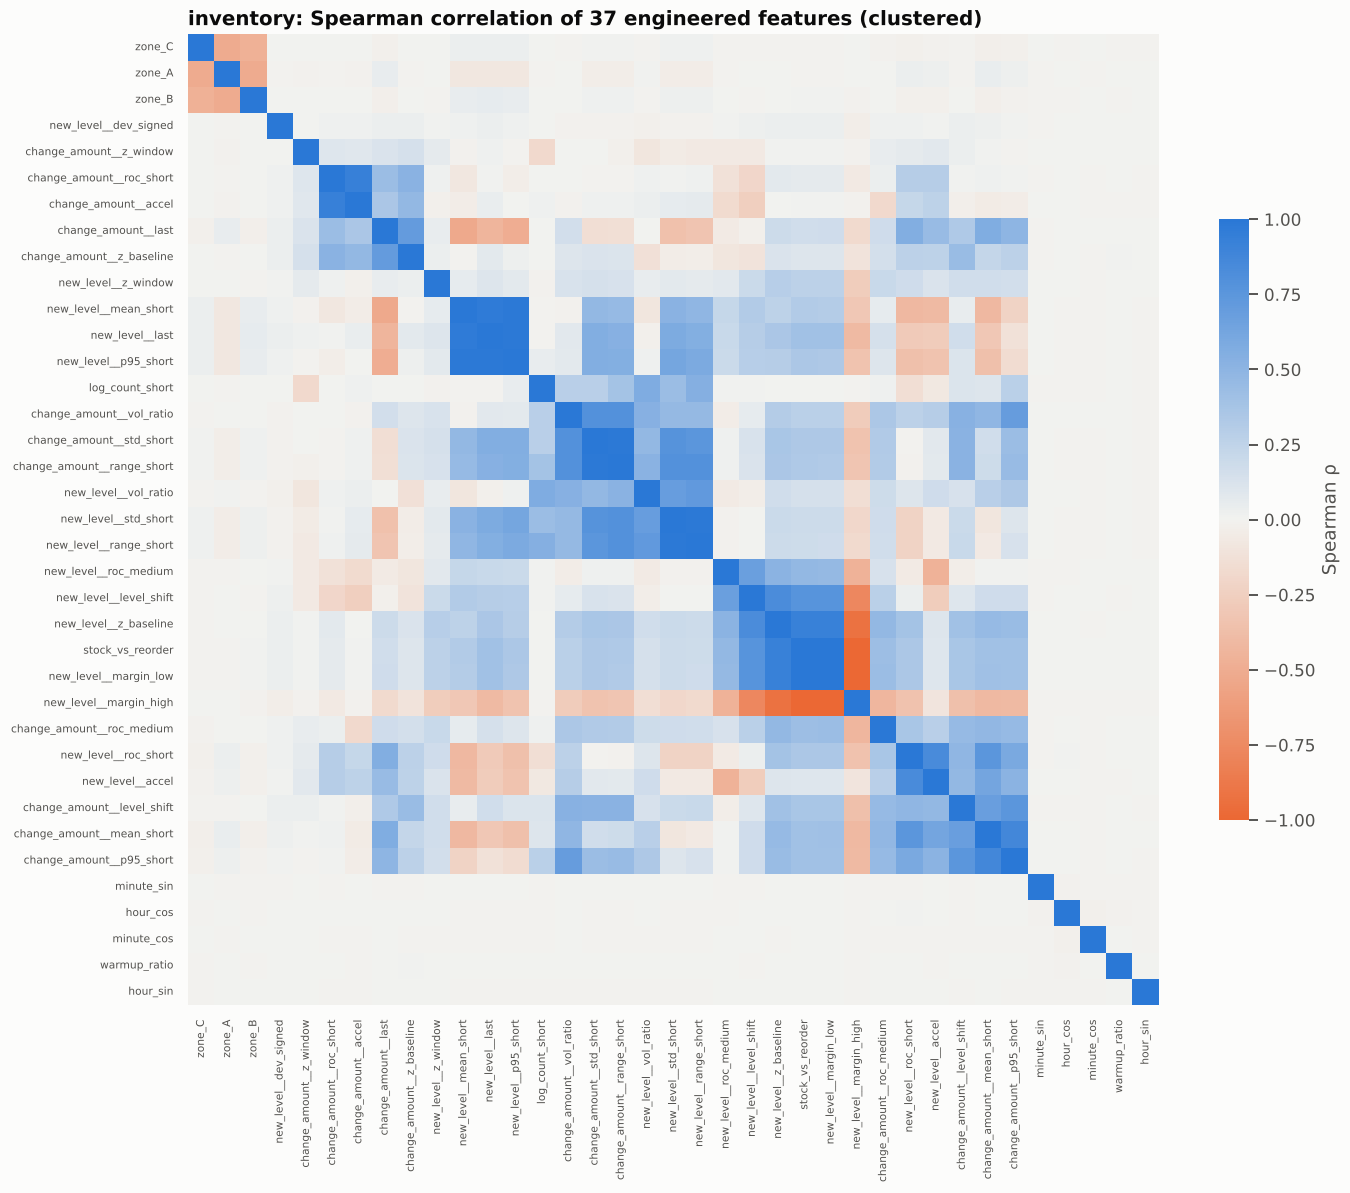

30 feature pairs with |ρ| ≥ 0.95 (redundancy candidates); per source: {'inventory': 8, 'vehicle': 13, 'warehouse': 9}


source,feature A,feature B,ρ
warehouse,value__margin_low,value__margin_high,-1.000
vehicle,speed_kmh__margin_low,speed_kmh__margin_high,-1.000
inventory,new_level__margin_low,new_level__margin_high,-1.000
vehicle,route_adherence_score__margin_high,route_adherence_score__last,-1.000
vehicle,route_adherence_score__last,route_adherence_score__margin_low,+1.000
vehicle,route_adherence_score__margin_high,route_adherence_score__margin_low,-1.000
inventory,stock_vs_reorder,new_level__margin_high,-1.000
inventory,stock_vs_reorder,new_level__margin_low,+1.000
vehicle,route_adherence_score__std_short,route_adherence_score__range_short,+0.992
inventory,change_amount__std_short,change_amount__range_short,+0.990


In [20]:
CORR, SAMPLE = {}, {}
for s in SOURCES:
    idx = np.flatnonzero(PREP[s]["warm"])
    idx = rng.choice(idx, min(60_000, len(idx)), replace=False)
    SAMPLE[s] = idx
    cols = PREP[s]["keep"]
    C = F[s].iloc[idx][cols].corr(method="spearman").fillna(0)
    d = 1 - C.abs().to_numpy(); np.fill_diagonal(d, 0); d = (d + d.T) / 2
    order = leaves_list(linkage(squareform(d, checks=False), "average"))
    names_o = [cols[i] for i in order]
    CORR[s] = C.loc[names_o, names_o]

for s, size in zip(SOURCES, [(10.5, 9), (13, 11.5), (13, 11.5)]):
    fig, ax = plt.subplots(figsize=size)
    sns.heatmap(CORR[s], cmap=DIV_CMAP, vmin=-1, vmax=1, square=True, xticklabels=True, yticklabels=True, linewidths=0,
                cbar_kws=dict(shrink=0.55, label="Spearman ρ"), ax=ax)
    ax.tick_params(labelsize=7)
    ax.set_title(f"{s}: Spearman correlation of {len(CORR[s])} engineered features (clustered)", loc="left", fontsize=13)
    plt.tight_layout(); plt.show()

pairs = []
for s in SOURCES:
    C = CORR[s]
    iu = np.triu_indices(len(C), 1)
    for i, j in zip(*iu):
        if abs(C.iat[i, j]) >= 0.95:
            pairs.append({"source": s, "feature A": C.index[i], "feature B": C.columns[j], "ρ": C.iat[i, j]})
pairs = pd.DataFrame(pairs)
print(f"{len(pairs)} feature pairs with |ρ| ≥ 0.95 (redundancy candidates); per source:", pairs.groupby("source").size().to_dict() if len(pairs) else {})
display(pairs.sort_values("ρ", key=abs, ascending=False).head(18).style.format({"ρ": "{:+.3f}"}).hide(axis="index"))

### 5.2 Mutual information between features and the anomaly label
Mutual information (k-NN estimator, `mutual_info_classif`) captures non-linear dependence that correlation misses. Because anomalies are rare, MI is estimated on a **re-balanced stratified sample** (all anomalies up to 6 000, plus 4× as many normals); the absolute values are therefore larger than at the natural prevalence, but the *ranking* is what we use. Warehouse also gets a multi-class MI against the four-way label (normal / point / contextual / collective).

In [21]:
from sklearn.feature_selection import mutual_info_classif

def impute(X: np.ndarray, med: np.ndarray | None = None) -> tuple[np.ndarray, np.ndarray]:
    med = np.nanmedian(X, axis=0) if med is None else med
    med = np.where(np.isfinite(med), med, 0.0)
    return np.where(np.isfinite(X), X, med), med

def strat_idx(s: str, n_pos_cap: int = 6000, ratio: int = 4) -> np.ndarray:
    warm, y = PREP[s]["warm"], PREP[s]["y"]
    pos, neg = np.flatnonzero(warm & y), np.flatnonzero(warm & ~y)
    pos = rng.choice(pos, min(len(pos), n_pos_cap), replace=False)
    neg = rng.choice(neg, min(len(neg), ratio * len(pos)), replace=False)
    return np.concatenate([pos, neg])

MI, STRAT = {}, {}
t0 = time.time()
for s in SOURCES:
    idx = STRAT[s] = strat_idx(s)
    X, _ = impute(F[s].iloc[idx][PREP[s]["keep"]].to_numpy(np.float64))
    MI[s] = pd.Series(mutual_info_classif(X, PREP[s]["y"][idx], n_neighbors=5, random_state=SEED), index=PREP[s]["keep"]).sort_values(ascending=False)
idx = STRAT["warehouse"]
Xw, _ = impute(F["warehouse"].iloc[idx][PREP["warehouse"]["keep"]].to_numpy(np.float64))
MI_multi = pd.Series(mutual_info_classif(Xw, pd.Categorical(F["warehouse"].label.iloc[idx], categories=TYPES).codes, n_neighbors=5, random_state=SEED),
                     index=PREP["warehouse"]["keep"]).sort_values(ascending=False)
print(f"MI computed in {time.time() - t0:.0f} s")

fig = make_subplots(rows=3, cols=1, vertical_spacing=0.09, subplot_titles=[f"{s} (binary label)" for s in SOURCES])
for k, s in enumerate(SOURCES, start=1):
    top = MI[s].head(15)[::-1]
    fig.add_bar(x=top.values, y=top.index, orientation="h", marker_color=BLUE, marker_line=dict(color=SURFACE, width=1.5), showlegend=False,
                hovertemplate="%{y}<br>MI %{x:.3f} nats<extra></extra>", row=k, col=1)
    fig.update_xaxes(title_text="mutual information (nats)" if k == 3 else None, row=k, col=1)
fig.update_layout(title="Top-15 features by mutual information with the anomaly label")
show(fig, 1180, margin=dict(t=84))

hdr("> **Caution on calendar features.** `hour_sin` / `hour_cos` rank high for the *vehicle* stream, yet the vehicle and inventory injectors have no time-of-day mechanism "
    "(only the warehouse *contextual* anomaly does). With ~70 episodes in one day, anomalies cluster in time by chance and the estimators credit the clock. "
    "§6.3 therefore excludes `hour_*`, `minute_*` and `dow_*` from the vehicle and inventory priority lists.")
hdr("**Warehouse — which features separate *which* anomaly class?** (multi-class MI, top 12)")
display(pd.DataFrame({"MI (binary)": MI["warehouse"], "MI (4-class)": MI_multi}).sort_values("MI (4-class)", ascending=False).head(12).round(3))

MI computed in 5 s


> **Caution on calendar features.** `hour_sin` / `hour_cos` rank high for the *vehicle* stream, yet the vehicle and inventory injectors have no time-of-day mechanism (only the warehouse *contextual* anomaly does). With ~70 episodes in one day, anomalies cluster in time by chance and the estimators credit the clock. §6.3 therefore excludes `hour_*`, `minute_*` and `dow_*` from the vehicle and inventory priority lists.

**Warehouse — which features separate *which* anomaly class?** (multi-class MI, top 12)

,MI (binary),MI (4-class)
value__margin_low,0.2910,0.4300
value__margin_high,0.2910,0.4290
value__z_baseline,0.2920,0.4210
value__z_window,0.2820,0.4000
value__dev_signed,0.2260,0.3600
value__last,0.2560,0.3520
value__range_short,0.0580,0.0880
value__vol_ratio,0.0570,0.0880
hour_cos,0.0220,0.0820
hour_sin,0.0190,0.0800


### 5.3 Baseline feature importance and a first separability number (Random Forest)
A deliberately plain supervised baseline — 100-tree Random Forest, class-balanced, **trained on `wh1` / vehicles 001-003 and scored on the held-out entities** — gives (a) a floor that Days 8–14 must beat, (b) impurity and **permutation importances** (average-precision drop, on a re-balanced test sample), and (c) per-class recall showing which anomaly type is hardest.

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

def best_f1(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / (pr + rc + 1e-12)
    i = int(np.nanargmax(f1[:-1]))
    return f1[i], pr[i], rc[i], th[i]

RF_RES, t0 = {}, time.time()
for s in SOURCES:
    P, df = PREP[s], F[s]
    tr = rng.choice(np.flatnonzero(P["warm"] & P["train"]), 150_000, replace=False) if (P["warm"] & P["train"]).sum() > 150_000 else np.flatnonzero(P["warm"] & P["train"])
    te_all = np.flatnonzero(P["warm"] & ~P["train"])
    te = rng.choice(te_all, 250_000, replace=False) if len(te_all) > 250_000 else te_all
    Xtr, med = impute(df.iloc[tr][P["keep"]].to_numpy(np.float64))
    Xte, _ = impute(df.iloc[te][P["keep"]].to_numpy(np.float64), med)
    rf = RandomForestClassifier(n_estimators=100, max_depth=14, min_samples_leaf=3, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=SEED).fit(Xtr, P["y"][tr])
    p = rf.predict_proba(Xte)[:, 1]
    yte = P["y"][te]
    f1, pr, rc, thr = best_f1(yte, p)
    flagged = p >= thr
    by_type = pd.Series(flagged, index=df.label.iloc[te].to_numpy()).groupby(level=0).mean()
    # permutation importance on a re-balanced test sample
    pos, neg = np.flatnonzero(yte), np.flatnonzero(~yte)
    sel = np.concatenate([rng.choice(pos, min(2000, len(pos)), replace=False), rng.choice(neg, min(8000, len(neg)), replace=False)])
    pi = permutation_importance(rf, Xte[sel], yte[sel], scoring="average_precision", n_repeats=2, random_state=SEED, n_jobs=1)
    RF_RES[s] = dict(n_train=len(tr), n_test=len(te), prevalence=yte.mean(), auc=roc_auc_score(yte, p), ap=average_precision_score(yte, p),
                     f1=f1, precision=pr, recall=rc, recall_by_type=by_type,
                     imp_impurity=pd.Series(rf.feature_importances_, index=P["keep"]).sort_values(ascending=False),
                     imp_perm=pd.Series(pi.importances_mean, index=P["keep"]).sort_values(ascending=False))
    print(f"{s:10s} done ({time.time() - t0:.0f} s elapsed)")

tbl = pd.DataFrame({s: {"train rows": r["n_train"], "test rows": r["n_test"], "test prevalence": r["prevalence"], "ROC-AUC": r["auc"],
                        "PR-AUC": r["ap"], "PR-AUC of a random guess": r["prevalence"], "best F1": r["f1"], "precision @ best F1": r["precision"],
                        "recall @ best F1": r["recall"]} for s, r in RF_RES.items()}).T
display(tbl.style.format({"train rows": "{:,.0f}", "test rows": "{:,.0f}", "test prevalence": "{:.2%}", "ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}",
                          "PR-AUC of a random guess": "{:.3f}", "best F1": "{:.3f}", "precision @ best F1": "{:.3f}", "recall @ best F1": "{:.3f}"}))
hdr("**Recall at the best-F1 threshold, per anomaly class (held-out entities)**")
display(pd.DataFrame({s: r["recall_by_type"] for s, r in RF_RES.items()}).reindex(TYPES).style.format("{:.1%}", na_rep="–"))

fig = make_subplots(rows=3, cols=1, vertical_spacing=0.09, subplot_titles=SOURCES)
for k, s in enumerate(SOURCES, start=1):
    top = RF_RES[s]["imp_perm"].head(12)[::-1]
    fig.add_bar(x=top.values, y=top.index, orientation="h", marker_color=ORANGE, marker_line=dict(color=SURFACE, width=1.5), showlegend=False,
                hovertemplate="%{y}<br>ΔPR-AUC %{x:.4f}<extra></extra>", row=k, col=1)
    fig.update_xaxes(title_text="drop in PR-AUC when the feature is shuffled" if k == 3 else None, row=k, col=1)
fig.update_layout(title="Permutation importance of the Random-Forest baseline (top 12, held-out entities)")
show(fig, 1000, margin=dict(t=84))

warehouse  done (22 s elapsed)


vehicle    done (27 s elapsed)


inventory  done (37 s elapsed)


,train rows,test rows,test prevalence,ROC-AUC,PR-AUC,PR-AUC of a random guess,best F1,precision @ best F1,recall @ best F1
warehouse,"150,000","250,000",3.23%,0.951,0.815,0.032,0.795,0.929,0.694
vehicle,"25,677","17,118",1.95%,0.979,0.947,0.020,0.957,0.984,0.931
inventory,"106,255","106,498",0.84%,0.999,0.987,0.008,0.969,0.988,0.951


**Recall at the best-F1 threshold, per anomaly class (held-out entities)**

,warehouse,vehicle,inventory
normal,0.2%,0.0%,0.0%
point,100.0%,100.0%,100.0%
contextual,29.6%,–,85.7%
collective,20.4%,73.3%,–


### 5.4 2-D PCA — are normal and anomalous classes separable?
Features are standardised and projected on the first two principal components (fitted on the re-balanced stratified sample). Plotted: all anomalies (≤ 2 500) over 5 000 normals. To make "looks separable" quantitative, a logistic regression is cross-validated on PC1–2 vs the first 10 PCs (ROC-AUC).

In [23]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

PCA_RES = {}
fig = make_subplots(rows=1, cols=3, horizontal_spacing=0.06, subplot_titles=SOURCES)
for k, s in enumerate(SOURCES, start=1):
    idx = STRAT[s]
    X, _ = impute(F[s].iloc[idx][PREP[s]["keep"]].to_numpy(np.float64))
    Z = StandardScaler().fit_transform(X)
    Z = np.clip(Z, -10, 10)
    pca = PCA(n_components=10, random_state=SEED).fit(Z)
    comp = pca.transform(Z)
    y = PREP[s]["y"][idx]
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    lr = LogisticRegression(max_iter=500, class_weight="balanced")
    auc2 = cross_val_score(lr, comp[:, :2], y, cv=cv, scoring="roc_auc").mean()
    auc10 = cross_val_score(lr, comp, y, cv=cv, scoring="roc_auc").mean()
    PCA_RES[s] = dict(evr=pca.explained_variance_ratio_, auc2=auc2, auc10=auc10)
    labels = F[s].label.iloc[idx].to_numpy()
    show_n = np.flatnonzero(labels == "normal")[:5000]
    for t in TYPES:
        sel = show_n if t == "normal" else np.flatnonzero(labels == t)[:2500]
        if len(sel) == 0:
            continue
        fig.add_scattergl(x=comp[sel, 0], y=comp[sel, 1], mode="markers", name=t, legendgroup=t, showlegend=(k == 1),
                          marker=dict(color=COL[t], size=3.5 if t == "normal" else 6, symbol=SYM[t], opacity=0.35 if t == "normal" else 0.8,
                                      line=dict(width=0)), row=1, col=k)
    fig.update_xaxes(title_text=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", row=1, col=k)
    fig.update_yaxes(title_text=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})" if k == 1 else None, row=1, col=k)
fig.update_layout(title="PCA of standardised features: normal vs anomaly classes")
show(fig, 520)
display(pd.DataFrame({s: {"PC1-2 variance": r["evr"][:2].sum(), "PC1-10 variance": r["evr"].sum(), "components for 90% var (of 10)": int(np.searchsorted(np.cumsum(r["evr"]), 0.9) + 1) if r["evr"].sum() >= 0.9 else ">10",
                          "CV ROC-AUC (PC1-2, linear)": r["auc2"], "CV ROC-AUC (PC1-10, linear)": r["auc10"]} for s, r in PCA_RES.items()}).T)

,PC1-2 variance,PC1-10 variance,components for 90% var (of 10),"CV ROC-AUC (PC1-2, linear)","CV ROC-AUC (PC1-10, linear)"
warehouse,0.4207,0.8906,>10,0.5412,0.7353
vehicle,0.5472,0.9019,10.0000,0.8503,0.9438
inventory,0.4161,0.7774,>10,0.7479,0.8578


### 5.5 Isolation-Forest contamination: what does the data support?
`contamination` does not change the trees — it only sets the score threshold (the share of points flagged). So we can study it directly: fit an Isolation Forest **without labels** on the training entities (100 trees, 2 048 samples each), score the held-out entities, then flag the top *q* % of scores and measure precision / recall / F1 against ground truth for a grid of *q*. The best-F1 *q* is the empirically supported contamination; it is compared with the true prevalence and with the `0.01` currently in `configs/config.yaml`.

In [24]:
from sklearn.ensemble import IsolationForest

GRID_Q = np.array([0.002, 0.005, 0.01, 0.015, 0.02, 0.025, 0.03, 0.04, 0.05, 0.07, 0.10, 0.15, 0.20])
IF_RES, sweeps, t0 = {}, [], time.time()
for s in SOURCES:
    P, df = PREP[s], F[s]
    tr_all = np.flatnonzero(P["warm"] & P["train"])
    tr = rng.choice(tr_all, min(100_000, len(tr_all)), replace=False)
    te_all = np.flatnonzero(P["warm"] & ~P["train"])
    te = rng.choice(te_all, min(200_000, len(te_all)), replace=False)
    Xtr, med = impute(df.iloc[tr][P["keep"]].to_numpy(np.float64))
    Xte, _ = impute(df.iloc[te][P["keep"]].to_numpy(np.float64), med)
    iso = IsolationForest(n_estimators=100, max_samples=2048, random_state=SEED, n_jobs=-1).fit(Xtr)
    score = -iso.score_samples(Xte)
    y = P["y"][te]
    for q in GRID_Q:
        flag = score >= np.quantile(score, 1 - q)
        tp = (flag & y).sum()
        pr, rc = tp / max(flag.sum(), 1), tp / max(y.sum(), 1)
        sweeps.append({"source": s, "q": q, "precision": pr, "recall": rc, "f1": 2 * pr * rc / (pr + rc + 1e-12)})
    sw = pd.DataFrame([r for r in sweeps if r["source"] == s])
    best = sw.loc[sw.f1.idxmax()]
    flag_b = score >= np.quantile(score, 1 - best.q)
    IF_RES[s] = dict(auc=roc_auc_score(y, score), ap=average_precision_score(y, score), prevalence=float(y.mean()), best_q=float(best.q),
                     best_f1=float(best.f1), recall_by_type=pd.Series(flag_b, index=df.label.iloc[te].to_numpy()).groupby(level=0).mean())
sweeps = pd.DataFrame(sweeps)
print(f"Isolation Forest sweeps done in {time.time() - t0:.0f} s")

fig = go.Figure()
cmap = {"warehouse": BLUE, "vehicle": ORANGE, "inventory": "#1baf7a"}
for s in SOURCES:
    d = sweeps[sweeps.source == s]
    b = IF_RES[s]
    fig.add_scatter(x=d.q, y=d.f1, mode="lines+markers", name=s, line=dict(color=cmap[s], width=2.2), marker=dict(size=7, line=dict(color=SURFACE, width=1)))
    fig.add_scatter(x=[b["best_q"]], y=[b["best_f1"]], mode="markers+text", marker=dict(size=14, symbol="star", color=cmap[s], line=dict(color=INK, width=1)),
                    text=[f"q={b['best_q']:.1%}"], textposition="top center", showlegend=False)
    fig.add_vline(x=b["prevalence"], line=dict(color=cmap[s], width=1, dash="dot"))
c0 = cfg.models.isolation_forest.contamination
fig.add_vline(x=c0, line=dict(color=INK2, width=1.5, dash="dash"))
fig.add_scatter(x=[None], y=[None], mode="lines", line=dict(color=INK2, width=1.5, dash="dash"), name=f"config.yaml contamination = {c0}")
fig.add_scatter(x=[None], y=[None], mode="lines", line=dict(color=INK2, width=1, dash="dot"), name="true prevalence (colour = source)")
fig.update_layout(title="Isolation Forest: F1 vs flagged fraction q (stars = best q)",
                  xaxis=dict(title="flagged fraction q (log scale)", type="log", tickvals=[0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2],
                             ticktext=["0.2%", "0.5%", "1%", "2%", "5%", "10%", "20%"], range=[np.log10(0.0016), np.log10(0.25)]),
                  yaxis=dict(title="F1 on held-out entities", range=[0, 1]))
show(fig, 460)
display(pd.DataFrame({s: {"ROC-AUC": r["auc"], "PR-AUC": r["ap"], "true prevalence": r["prevalence"], "best-F1 q": r["best_q"], "F1 at best q": r["best_f1"]}
                      for s, r in IF_RES.items()}).T.style.format({"ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}", "true prevalence": "{:.2%}", "best-F1 q": "{:.1%}", "F1 at best q": "{:.3f}"}))
hdr("**Isolation-Forest recall per class at its best-F1 threshold**")
display(pd.DataFrame({s: r["recall_by_type"] for s, r in IF_RES.items()}).reindex(TYPES).style.format("{:.1%}", na_rep="–"))

Isolation Forest sweeps done in 3 s


,ROC-AUC,PR-AUC,true prevalence,best-F1 q,F1 at best q
warehouse,0.894,0.627,3.21%,2.5%,0.633
vehicle,0.955,0.777,1.95%,1.5%,0.731
inventory,0.950,0.134,0.84%,1.0%,0.222


**Isolation-Forest recall per class at its best-F1 threshold**

,warehouse,vehicle,inventory
normal,0.7%,0.2%,0.8%
point,93.7%,87.1%,18.3%
contextual,4.3%,–,35.7%
collective,5.5%,0.0%,–


---
## 6 · Key findings and documented decisions

The cells below *compute* every number they quote from the analyses above, so the conclusions stay correct if the seed, duration or simulator parameters change. Static commentary only restates **why** a number was chosen.

### 6.1 Recommended LSTM lookback window
**Rule.** A sequence model must (a) cover the longest *collective* episode plus some normal context before its onset, and (b) span the signal's autocorrelation memory. We take
`lookback = max( PACF order of the signal , ⌈1.5 × p95 collective-episode length⌉ rounded up to 5 )`.
Inventory has no collective anomaly; there the context that matters is the position in the restock saw-tooth, so we take half a restock cycle (in events) instead of an episode length, clipped to 10–60 steps.

In [25]:
def ceil_to(x: float, m: int) -> int:
    return int(math.ceil(x / m) * m)

gps_ep = gps[gps.is_anomaly].groupby(["vehicle_id", "episode_id"]).agg(type=("label", "first"), sub=("subtype", "first"), n=("ts", "size")).reset_index()
coll_len = {"warehouse": wh_ep[wh_ep.type == "collective"].n, "vehicle": gps_ep[gps_ep["sub"] == "gradual_delay"].n}

inv["k"] = inv.groupby("sku_id").cumcount()
cycles = inv[(inv.ttype == "restock") & ~inv.is_anomaly].groupby("sku_id").k.diff().dropna()
cycle_med = float(cycles.median())

PRIMARY = {"warehouse": ["temperature", "humidity"], "vehicle": ["speed_kmh", "route_adherence"], "inventory": ["change_amount"]}
def acf_stat(src: str, col: str, variant: str = "all") -> int:
    d = acf_summary[(acf_summary.source == src) & acf_summary.signal.isin(PRIMARY[src]) & (acf_summary.variant == variant)]
    return int(d[col].max())

lookback, rows = {}, []
for s in SOURCES:
    pacf_all, pacf_norm = acf_stat(s, "PACF order (last |PACF|≥0.1)"), acf_stat(s, "PACF order (last |PACF|≥0.1)", "normal")
    mem = acf_stat(s, "memory lag (first |ACF|<0.1)")
    if s == "inventory":
        L = int(np.clip(ceil_to(max(pacf_all, 0.5 * cycle_med), 5), 10, 60)); basis = f"½ restock cycle ({cycle_med:.0f} events)"; p95 = np.nan
    else:
        p95 = float(coll_len[s].quantile(0.95)); L = max(pacf_all, ceil_to(1.5 * p95, 5)); basis = f"1.5 × p95 collective length ({p95:.0f})"
    lookback[s] = int(L)
    rows.append({"source": s, "PACF order (all)": pacf_all, "PACF order (normal)": pacf_norm, "ACF memory lag": mem, "limiting factor": basis, "recommended lookback (steps)": int(L),
                 "≈ wall-clock": {"warehouse": f"{L} s", "vehicle": f"{L * 10 / 60:.1f} min", "inventory": "irregular"}[s]})
lb = pd.DataFrame(rows)
display(lb.style.hide(axis="index"))
cfg_ae, cfg_clf = cfg.models.lstm_autoencoder.seq_len, cfg.models.lstm_classifier.seq_len
print(f"config.yaml today: lstm_autoencoder.seq_len = {cfg_ae}, lstm_classifier.seq_len = {cfg_clf}")
print(f"longest warehouse collective episode = {int(coll_len['warehouse'].max())} readings; longest vehicle gradual_delay = {int(coll_len['vehicle'].max())} readings.")

source,PACF order (all),PACF order (normal),ACF memory lag,limiting factor,recommended lookback (steps),≈ wall-clock
warehouse,2,0,4,1.5 × p95 collective length (29),45,45 s
vehicle,2,0,9,1.5 × p95 collective length (28),45,7.5 min
inventory,0,0,1,½ restock cycle (17 events),10,irregular


config.yaml today: lstm_autoencoder.seq_len = 60, lstm_classifier.seq_len = 30
longest warehouse collective episode = 30 readings; longest vehicle gradual_delay = 29 readings.


### 6.2 Recommended Isolation-Forest `contamination`

In [26]:
prev_warm = {s: float(F[s][PREP[s]["warm"]].is_anomaly.mean()) for s in SOURCES}
contam = {s: IF_RES[s]["best_q"] for s in SOURCES}
cdf = pd.DataFrame({"true prevalence (warm rows)": prev_warm, "best-F1 q (held-out)": contam,
                    "F1 at best q": {s: IF_RES[s]["best_f1"] for s in SOURCES}, "F1 at config 0.01": {s: float(sweeps[(sweeps.source == s) & np.isclose(sweeps.q, 0.01)].f1.iloc[0]) for s in SOURCES},
                    "IF ROC-AUC": {s: IF_RES[s]["auc"] for s in SOURCES}})
display(cdf.style.format({"true prevalence (warm rows)": "{:.2%}", "best-F1 q (held-out)": "{:.1%}", "F1 at best q": "{:.3f}", "F1 at config 0.01": "{:.3f}", "IF ROC-AUC": "{:.3f}"}))
print(f"config.yaml today: models.isolation_forest.contamination = {cfg.models.isolation_forest.contamination} (one value for all sources)")

,true prevalence (warm rows),best-F1 q (held-out),F1 at best q,F1 at config 0.01,IF ROC-AUC
warehouse,3.34%,2.5%,0.633,0.451,0.894
vehicle,2.19%,1.5%,0.731,0.676,0.955
inventory,0.88%,1.0%,0.222,0.222,0.950


config.yaml today: models.isolation_forest.contamination = 0.01 (one value for all sources)


### 6.3 Features to prioritise (and drop)
Each feature is ranked by the **average of its MI rank and its permutation-importance rank** (calendar features are excluded for vehicle and inventory, see the caution in §5.2); walking down that list, a feature is kept unless it is ≥ 0.95 |ρ| correlated with an already-kept, better-ranked feature. This yields a short, non-redundant priority list per source.

In [27]:
TOP_K = 12
priority, redundant, rows = {}, {}, []
for s in SOURCES:
    r = pd.DataFrame({"mi": MI[s], "perm": RF_RES[s]["imp_perm"]}).fillna(0)
    if s != "warehouse":  # no time-of-day mechanism in these injectors -> calendar credit is a 24 h artefact
        r = r[~r.index.str.match(r"^(hour|minute|dow)_")]
    r["rank"] = r.mi.rank(ascending=False) + r.perm.rank(ascending=False)
    r = r.sort_values("rank")
    C = CORR[s]
    kept, dropped = [], {}
    for f in r.index:
        twin = next((g for g in kept if abs(C.at[f, g]) >= 0.95), None)
        if twin is None:
            kept.append(f)
        else:
            dropped[f] = twin
    priority[s] = kept[:TOP_K]; redundant[s] = dropped
    for pos, f in enumerate(kept[:TOP_K], start=1):
        rows.append({"source": s, "#": pos, "feature": f, "MI": r.at[f, "mi"], "perm. importance": r.at[f, "perm"]})
pt = pd.DataFrame(rows)
display(pt.pivot(index="#", columns="source", values="feature")[SOURCES])
print("Dropped as redundant (|ρ| ≥ 0.95 with a better-ranked feature):")
for s in SOURCES:
    print(f"  {s:10s} {len(redundant[s]):2d} -> " + ", ".join(f"{f}≈{g}" for f, g in list(redundant[s].items())[:8]) + (" …" if len(redundant[s]) > 8 else ""))

source,warehouse,vehicle,inventory
#,,,
1,value__margin_low,speed_kmh__margin_low,change_amount__z_baseline
2,value__z_window,speed_kmh__level_shift,change_amount__last
3,hour_cos,route_adherence_score__dev_signed,change_amount__level_shift
4,value__dev_signed,speed_kmh__last,change_amount__range_short
5,value__roc_short,route_adherence_score__last,new_level__vol_ratio
6,hour_sin,route_adherence_score__level_shift,change_amount__vol_ratio
7,value__range_short,speed_kmh__roc_medium,new_level__range_short
8,value__last,speed_kmh__p95_short,stock_vs_reorder
9,value__vol_ratio,route_adherence_score__mean_short,change_amount__roc_medium


Dropped as redundant (|ρ| ≥ 0.95 with a better-ranked feature):
  warehouse   6 -> value__margin_high≈value__margin_low, value__z_baseline≈value__margin_low, value__accel≈value__roc_short, value__p95_short≈value__last, value__mean_short≈value__last, value__std_short≈value__range_short
  vehicle     9 -> speed_kmh__margin_high≈speed_kmh__margin_low, route_adherence_score__margin_high≈route_adherence_score__last, route_adherence_score__margin_low≈route_adherence_score__last, speed_kmh__z_baseline≈speed_kmh__margin_low, speed_kmh__accel≈speed_kmh__roc_short, speed_kmh__mean_short≈speed_kmh__p95_short, speed_kmh__z_window≈speed_kmh__margin_low, route_adherence_score__std_short≈route_adherence_score__range_short …
  inventory   6 -> new_level__margin_high≈stock_vs_reorder, new_level__margin_low≈stock_vs_reorder, new_level__std_short≈new_level__range_short, change_amount__std_short≈change_amount__range_short, new_level__mean_short≈new_level__p95_short, new_level__last≈new_level__p95_short


### 6.4 Summary of findings

In [28]:
def pct(x: float, d: int = 1) -> str:
    return f"{100 * x:.{d}f}%"

R = {s: RF_RES[s] for s in SOURCES}
imb_rows = imb[imb.source.isin(SOURCES)].set_index(["source", "class"])
def n_rows(s, c): return int(imb_rows.at[(s, c), "rows"])
def n_eps(s, c): return int(imb_rows.at[(s, c), "episodes"])

ranges = range_tbl["flagged by a plain range check"]
lad_a = sigma_ladder[(sigma_ladder.variant == "per SKU") & (sigma_ladder["k (σ)"] == 5)].iloc[0]
lad_b = sigma_ladder[(sigma_ladder.variant == "per SKU x transaction type") & (sigma_ladder["k (σ)"] == 5)].iloc[0]
ghost_above = float((ghost.svr > 0).mean())
rs_above = float((rs[~rs.is_anomaly].svr > 0).mean())
dev_row = gps[gps.subtype == "route_deviation"]
const_all = sorted({c for s in SOURCES for c in PREP[s]["const"]})

pos_w = {s: (len(F[s]) - F[s].is_anomaly.sum()) / F[s].is_anomaly.sum() for s in SOURCES}
txt = f"""
**1 · Class imbalance (§1.3).** Row-level anomaly rates are {pct(wh.is_anomaly.mean())} (warehouse), {pct(gps.is_anomaly.mean())} (vehicle) and {pct(inv.is_anomaly.mean())} (inventory) — normal : anomaly of
{1/wh.is_anomaly.mean():.0f}:1, {1/gps.is_anomaly.mean():.0f}:1 and {1/inv.is_anomaly.mean():.0f}:1. In *episodes* the picture is far thinner: warehouse has {n_eps('warehouse','point')} point, {n_eps('warehouse','contextual')} contextual and {n_eps('warehouse','collective')} collective incidents,
vehicle {n_eps('vehicle','point')} point / {n_eps('vehicle','collective')} collective, inventory {n_eps('inventory','point')} point / {n_eps('inventory','contextual')} contextual — a 24 h run is enough for EDA but thin for training.
→ Use `pos_weight ≈ {pos_w['warehouse']:.0f} / {pos_w['vehicle']:.0f} / {pos_w['inventory']:.0f}` (warehouse / vehicle / inventory) or focal loss; judge models by **PR-AUC and F1, never accuracy** (always-normal scores {pct(1 - wh.is_anomaly.mean())}+);
**split by entity or by whole episodes, never by random rows** (rows inside an episode are near-duplicates).

**2 · Warehouse (§2).** A plain range check flags {pct(ranges['point'])} of *point*, {pct(ranges['contextual'])} of *contextual* and {pct(ranges['collective'])} of *collective* readings: {pct(ctx_inside)} of contextual readings are inside the range, so they exist only relative to the hour of day
(contextual episodes are confined to 00–05). Drifts are only visible as a sequence. → statistical baselines (z-score / IQR) are expected to catch point anomalies, CUSUM the drifts, and contextual needs the calendar and level-shift / volatility-ratio features.

**3 · GPS (§3).** Route deviations leave speed untouched ({pct(dev_row.speed_ratio.between(0.6, 1.2).mean(), 0)} of deviating readings are inside the normal speed band) but drive the adherence score down to a median of {dev_row.adherence.median():.2f}
versus {gps[~gps.is_anomaly].adherence.median():.3f} normally — **`route_adherence_score` features are mandatory**; speed features cover stops, excessive speed and (as a sequence) gradual delays.

**4 · Inventory (§4).** Restocks are themselves multi-sigma events: with σ estimated per SKU, a "flag > 5σ" rule flags {int(lad_a['flagged']):,} events with a precision of only {pct(lad_a['precision'], 0)}
({pct(lad_a['false alarms that are normal restocks'], 0)} of its false alarms are legitimate restocks), and any threshold low enough to catch the drops keeps them (up to 20σ); beyond ~30σ the rule flags almost nothing. Judging every event against *its own transaction type* fixes the drops
(5σ catches {pct(lad_b['recall sudden_drop'], 0)} of sudden drops at {pct(lad_b['precision'], 0)} precision) but sees only {pct(lad_b['recall ghost_stock'], 0)} of ghost stock, which has exactly the size and booking type of a real restock.
{pct(ghost_above, 0)} of ghost-stock events occur above the reorder point whereas only {pct(rs_above, 1)} of genuine restocks do → `stock_vs_reorder` (context) is the discriminating feature; magnitude alone is not.

**5 · Separability and baselines (§5).** On unseen entities a plain Random Forest reaches PR-AUC {R['warehouse']['ap']:.2f} / {R['vehicle']['ap']:.2f} / {R['inventory']['ap']:.2f} (warehouse / vehicle / inventory; random guess = {pct(R['warehouse']['prevalence'])} / {pct(R['vehicle']['prevalence'])} / {pct(R['inventory']['prevalence'])})
and the unsupervised Isolation Forest reaches ROC-AUC {IF_RES['warehouse']['auc']:.2f} / {IF_RES['vehicle']['auc']:.2f} / {IF_RES['inventory']['auc']:.2f}. These are the numbers Days 8–14 have to beat. The PC1–2 linear ROC-AUCs are {PCA_RES['warehouse']['auc2']:.2f} / {PCA_RES['vehicle']['auc2']:.2f} / {PCA_RES['inventory']['auc2']:.2f}
(vs {PCA_RES['warehouse']['auc10']:.2f} / {PCA_RES['vehicle']['auc10']:.2f} / {PCA_RES['inventory']['auc10']:.2f} with ten PCs): see the scatter for which classes overlap the normal cloud.
"""
display(Markdown(txt))

decisions = f"""
### Decisions for Days 8–14

| Decision | Value | Evidence |
|---|---|---|
| **LSTM lookback** (warehouse / vehicle / inventory) | **{lookback['warehouse']} / {lookback['vehicle']} / {lookback['inventory']} steps** (config today: AE {cfg_ae}, classifier {cfg_clf}) | §2.5 ACF/PACF, episode lengths §2.4, §6.1 |
| **Isolation-Forest contamination** | **{pct(contam['warehouse'])} / {pct(contam['vehicle'])} / {pct(contam['inventory'])}** per source (config today: {pct(cfg.models.isolation_forest.contamination)} for all) | §5.5 sweep; true prevalence {pct(prev_warm['warehouse'])} / {pct(prev_warm['vehicle'])} / {pct(prev_warm['inventory'])} |
| **Warehouse features to prioritise** | {', '.join(f'`{f}`' for f in priority['warehouse'][:8])} | MI + permutation importance, §5.2–5.3 |
| **Vehicle features to prioritise** | {', '.join(f'`{f}`' for f in priority['vehicle'][:8])} | idem |
| **Inventory features to prioritise** | {', '.join(f'`{f}`' for f in priority['inventory'][:8])} | idem |
| **Drop (calendar, vehicle & inventory)** | `hour_*`, `minute_*`, `dow_*` | §5.2 caution: no time-of-day mechanism, high MI is a 24 h artefact |
| **Drop (constant offline)** | {', '.join(f'`{f}`' for f in const_all)} | §5.0 — need `EntityHistory` feedback / more than one day |
| **Drop (redundant, \\|ρ\\| ≥ 0.95)** | {sum(len(v) for v in redundant.values())} features, listed in §6.3 | §5.1 |
| **Training split** | by entity / whole episodes; chronological needs ≥ 2 days | §5.0 contextual anomalies only 00–05 |
| **Metrics** | PR-AUC, F1 per class, recall per anomaly type | §1.3, §5.3 |
"""
display(Markdown(decisions))


**1 · Class imbalance (§1.3).** Row-level anomaly rates are 3.4% (warehouse), 2.2% (vehicle) and 0.9% (inventory) — normal : anomaly of
30:1, 46:1 and 114:1. In *episodes* the picture is far thinner: warehouse has 6696 point, 1555 contextual and 257 collective incidents,
vehicle 110 point / 17 collective, inventory 1243 point / 647 contextual — a 24 h run is enough for EDA but thin for training.
→ Use `pos_weight ≈ 29 / 45 / 113` (warehouse / vehicle / inventory) or focal loss; judge models by **PR-AUC and F1, never accuracy** (always-normal scores 96.6%+);
**split by entity or by whole episodes, never by random rows** (rows inside an episode are near-duplicates).

**2 · Warehouse (§2).** A plain range check flags 100.0% of *point*, 0.0% of *contextual* and 5.5% of *collective* readings: 100.0% of contextual readings are inside the range, so they exist only relative to the hour of day
(contextual episodes are confined to 00–05). Drifts are only visible as a sequence. → statistical baselines (z-score / IQR) are expected to catch point anomalies, CUSUM the drifts, and contextual needs the calendar and level-shift / volatility-ratio features.

**3 · GPS (§3).** Route deviations leave speed untouched (100% of deviating readings are inside the normal speed band) but drive the adherence score down to a median of 0.05
versus 1.000 normally — **`route_adherence_score` features are mandatory**; speed features cover stops, excessive speed and (as a sequence) gradual delays.

**4 · Inventory (§4).** Restocks are themselves multi-sigma events: with σ estimated per SKU, a "flag > 5σ" rule flags 13,950 events with a precision of only 14%
(100% of its false alarms are legitimate restocks), and any threshold low enough to catch the drops keeps them (up to 20σ); beyond ~30σ the rule flags almost nothing. Judging every event against *its own transaction type* fixes the drops
(5σ catches 100% of sudden drops at 100% precision) but sees only 7% of ghost stock, which has exactly the size and booking type of a real restock.
100% of ghost-stock events occur above the reorder point whereas only 0.0% of genuine restocks do → `stock_vs_reorder` (context) is the discriminating feature; magnitude alone is not.

**5 · Separability and baselines (§5).** On unseen entities a plain Random Forest reaches PR-AUC 0.82 / 0.95 / 0.99 (warehouse / vehicle / inventory; random guess = 3.2% / 2.0% / 0.8%)
and the unsupervised Isolation Forest reaches ROC-AUC 0.89 / 0.95 / 0.95. These are the numbers Days 8–14 have to beat. The PC1–2 linear ROC-AUCs are 0.54 / 0.85 / 0.75
(vs 0.74 / 0.94 / 0.86 with ten PCs): see the scatter for which classes overlap the normal cloud.



### Decisions for Days 8–14

| Decision | Value | Evidence |
|---|---|---|
| **LSTM lookback** (warehouse / vehicle / inventory) | **45 / 45 / 10 steps** (config today: AE 60, classifier 30) | §2.5 ACF/PACF, episode lengths §2.4, §6.1 |
| **Isolation-Forest contamination** | **2.5% / 1.5% / 1.0%** per source (config today: 1.0% for all) | §5.5 sweep; true prevalence 3.3% / 2.2% / 0.9% |
| **Warehouse features to prioritise** | `value__margin_low`, `value__z_window`, `hour_cos`, `value__dev_signed`, `value__roc_short`, `hour_sin`, `value__range_short`, `value__last` | MI + permutation importance, §5.2–5.3 |
| **Vehicle features to prioritise** | `speed_kmh__margin_low`, `speed_kmh__level_shift`, `route_adherence_score__dev_signed`, `speed_kmh__last`, `route_adherence_score__last`, `route_adherence_score__level_shift`, `speed_kmh__roc_medium`, `speed_kmh__p95_short` | idem |
| **Inventory features to prioritise** | `change_amount__z_baseline`, `change_amount__last`, `change_amount__level_shift`, `change_amount__range_short`, `new_level__vol_ratio`, `change_amount__vol_ratio`, `new_level__range_short`, `stock_vs_reorder` | idem |
| **Drop (calendar, vehicle & inventory)** | `hour_*`, `minute_*`, `dow_*` | §5.2 caution: no time-of-day mechanism, high MI is a 24 h artefact |
| **Drop (constant offline)** | `anomaly_rate_7d`, `dow_cos`, `dow_sin`, `log_count_short`, `reliability`, `time_since_last_anomaly_log` | §5.0 — need `EntityHistory` feedback / more than one day |
| **Drop (redundant, \|ρ\| ≥ 0.95)** | 21 features, listed in §6.3 | §5.1 |
| **Training split** | by entity / whole episodes; chronological needs ≥ 2 days | §5.0 contextual anomalies only 00–05 |
| **Metrics** | PR-AUC, F1 per class, recall per anomaly type | §1.3, §5.3 |


### 6.5 Open issues found while doing the EDA

1. **`lstm_classifier.class_names` has no `collective` class.** `configs/config.yaml` lists `[normal, point, contextual]`, but both the warehouse and GPS simulators emit `collective` anomalies (§1.3). Either add the class on Day 12 or document that drifts are left to the autoencoder / CUSUM.
2. **24 simulated hours are too short for time-split evaluation of contextual anomalies** (§5.0): they only occur 00:00–05:00. Generate ≥ 3–7 days for Day 8+ (also makes `dow_sin` / `dow_cos` informative and lets `EntityHistory` features be exercised).
3. **`EntityHistory` features are constant offline** (`time_since_last_anomaly_log`, `anomaly_rate_7d`, `reliability`). They only become informative once detector output is fed back; keep them out of offline training or replay detections to build them without leaking labels.
4. **Cold start**: the first ~15 minutes per entity have no valid long-window baseline; training sets should drop rows with `warmup_ratio < 0.9` (as done here) and the serving path should suppress alerts until warm.
5. **Order-fulfilment stream** is disabled in the default config and has no feature schema yet, so it is not part of this EDA.

In [29]:
# ---- Persist the decisions so Day 8+ code can read them instead of re-deriving them -----------
out_dir = ROOT / "reports" / "eda"
out_dir.mkdir(parents=True, exist_ok=True)
findings = {
    "generated_utc": datetime.now(UTC).isoformat(timespec="seconds"),
    "simulation": {"seed": cfg.simulation.seed, "hours": HOURS, "start": START.isoformat(), "orders": False},
    "class_balance": {s: {"rows": int(len(df)), "anomaly_rate": float(df.is_anomaly.mean()),
                          "by_class": {k: int(v) for k, v in df.label.value_counts().items()}}
                      for s, df in [("warehouse", wh), ("vehicle", gps), ("inventory", inv)]},
    "lstm_lookback": lookback,
    "isolation_forest_contamination": {s: float(v) for s, v in contam.items()},
    "isolation_forest_prevalence": prev_warm,
    "feature_priority": priority,
    "features_constant_offline": {s: PREP[s]["const"] for s in SOURCES},
    "features_redundant": {s: redundant[s] for s in SOURCES},
    "baselines_heldout_entities": {
        "random_forest": {s: {"pr_auc": float(R[s]["ap"]), "roc_auc": float(R[s]["auc"]), "best_f1": float(R[s]["f1"])} for s in SOURCES},
        "isolation_forest": {s: {"roc_auc": float(IF_RES[s]["auc"]), "pr_auc": float(IF_RES[s]["ap"]), "best_f1": float(IF_RES[s]["best_f1"])} for s in SOURCES},
    },
    "pos_weight": {s: float(v) for s, v in pos_w.items()},
}
(out_dir / "eda_findings.json").write_text(json.dumps(findings, indent=2))
print("wrote", (out_dir / "eda_findings.json").relative_to(ROOT))
print(f"\nenvironment: python {sys.version.split()[0]} · numpy {np.__version__} · pandas {pd.__version__} · seaborn {sns.__version__} · "
      f"plotly {__import__('plotly').__version__} · sklearn {__import__('sklearn').__version__} · seed {SEED}")

wrote reports/eda/eda_findings.json

environment: python 3.13.18 · numpy 2.5.3 · pandas 3.0.5 · seaborn 0.13.2 · plotly 7.1.0 · sklearn 1.9.1 · seed 42
